# IoT Device Classification: JA4 + JA4X
## Random Forest vs. CatBoost vs. Dictionary Matching on UNSW-IoTraffic and CIC-IoT-2023

### HW & SW definition

In [2]:
import sys
import platform
import psutil
import os
import pandas as pd
import numpy as np
import sklearn
import catboost
import statsmodels

def get_complete_environment_specs():
    specs = {}
    uname = platform.uname()
    specs["Machine Architecture"] = uname.machine
    specs["Processor Type"] = uname.processor if uname.processor else platform.processor()
    specs["Physical CPU Cores"] = psutil.cpu_count(logical=False)
    specs["Logical CPU Cores (Threads)"] = psutil.cpu_count(logical=True)
    cpu_freq = psutil.cpu_freq()
    if cpu_freq:
        specs["CPU Current Frequency"] = f"{cpu_freq.current:.2f} MHz"
        specs["CPU Max Frequency"] = f"{cpu_freq.max:.2f} MHz" if cpu_freq.max else "N/A"
    ram = psutil.virtual_memory()
    specs["Total System RAM"] = f"{ram.total / (1024**3):.2f} GB"
    specs["Available System RAM"] = f"{ram.available / (1024**3):.2f} GB"
    specs["Python Version"] = sys.version.split()[0]
    specs["Random Forest Engine (Scikit-Learn)"] = sklearn.__version__
    specs["CatBoost Version"] = catboost.__version__
    specs["Statsmodels Version"] = statsmodels.__version__
    specs["Pandas Version"] = pd.__version__
    specs["NumPy Version"] = np.__version__
    return specs

full_env_metadata = get_complete_environment_specs()
print("=" * 80)
print("COMPLETE EXPERIMENTAL SETUP REPORT: JA4 + JA4X")
print("=" * 80)
for key, value in full_env_metadata.items():
    print(f" • {key}: {value}")
print("=" * 80)

COMPLETE EXPERIMENTAL SETUP REPORT: JA4 + JA4X
 • Machine Architecture: AMD64
 • Processor Type: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
 • Physical CPU Cores: 4
 • Logical CPU Cores (Threads): 8
 • CPU Current Frequency: 1803.00 MHz
 • CPU Max Frequency: 2304.00 MHz
 • Total System RAM: 15.71 GB
 • Available System RAM: 2.02 GB
 • Python Version: 3.13.14
 • Random Forest Engine (Scikit-Learn): 1.8.0
 • CatBoost Version: 1.2.10
 • Statsmodels Version: 0.15.0
 • Pandas Version: 3.0.2
 • NumPy Version: 2.4.4


### Purpose and reviewer traceability

This notebook evaluates the complete JA4X fingerprint bundle: `ja4`, `ja4s`, `ja4x`, `ja4t` and `ja4ts`. The compact representation uses all five signatures; the decomposed representation uses the JA4, JA4S, JA4T, JA4TS and JA4X fields defined for this experiment.

The same filtering policy, per-device split, Random Forest, CatBoost and Dictionary Matching benchmark are applied to UNSW-IoTraffic and CIC-IoT-2023. Rows are retained only when all five selected signatures are available.

In [3]:
import os
import time
import sys
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    top_k_accuracy_score,
    classification_report,
    make_scorer,
)
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import ttest_rel
from catboost import CatBoostClassifier

pd.set_option("display.float_format", lambda value: f"{value:.4f}")

DATASETS_CONFIG = {
    "UNSW": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    },
    "CIC_IOT": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    }
}

OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(OUTPUT_DIR, exist_ok=True)
EXCEL_PATH = os.path.join(OUTPUT_DIR, "Comparativa_Modelos_Avanzada_JA4X_All_Fingerprints.xlsx")

## 1. Exploratory Data Analysis, Fingerprint Inspection, and Filtering Audit

This JA4X experiment combines the five compact signatures `ja4`, `ja4s`, `ja4x`, `ja4t` and `ja4ts`. The section reports sample and device-class counts before and after filtering and measures repetition across the complete five-signature bundle. Rows are retained only when all five signatures are present and valid.

The decomposed representation uses the JA4, JA4S, JA4T, JA4TS and JA4X fields listed in `DECOMPOSED_FEATURES`; numeric and categorical fields are defined separately for preprocessing.

In [18]:
COMBINATION_NAME = "JA4 + JA4X"
SIGNATURE_COLUMNS = ["ja4", "ja4x"]
DECOMPOSED_FEATURES = [
    "ja4_protocol", "ja4_tls_version", "ja4_sni_type", "ja4_n_ciphers", "ja4_n_extensions",
    "ja4_alpn", "ja4_cipher_hash", "ja4_extension_hash",
    "ja4x_issuer_hash", "ja4x_subject_hash", "ja4x_extensions_hash"
]
NUMERIC_DECOMPOSED = ["ja4_n_ciphers", "ja4_n_extensions"]
CATEGORICAL_DECOMPOSED = [c for c in DECOMPOSED_FEATURES if c not in NUMERIC_DECOMPOSED]
FULL_FEATURES = SIGNATURE_COLUMNS.copy()
TARGET_COL = "device_name"


def analyze_and_clean_dataset(csv_path, min_samples=5, max_samples=500, dataset_name="Dataset"):
    print("=" * 80)
    print(f"EXPLORATORY AUDIT & FILTERING ANALYSIS: {COMBINATION_NAME} | {dataset_name}")
    print("=" * 80)

    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    init_samples = len(df_raw)
    init_classes = df_raw[TARGET_COL].nunique()

    valid_mask = pd.Series(True, index=df_raw.index)
    for column in SIGNATURE_COLUMNS:
        values = df_raw[column].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])
    df_valid = df_raw[valid_mask].copy()

    df_valid["fingerprint_bundle"] = df_valid[FULL_FEATURES].agg(" | ".join, axis=1)
    total_fingerprints = len(df_valid)
    unique_fingerprints = df_valid["fingerprint_bundle"].nunique()
    repeated_fingerprints = total_fingerprints - unique_fingerprints

    print(f"[Fingerprint Stats] Total valid samples: {total_fingerprints}")
    print(f"[Fingerprint Stats] Unique {COMBINATION_NAME} fingerprints: {unique_fingerprints} ({unique_fingerprints/total_fingerprints*100:.2f}%)")
    print(f"[Fingerprint Stats] Repeated {COMBINATION_NAME} fingerprints: {repeated_fingerprints} ({repeated_fingerprints/total_fingerprints*100:.2f}%)")

    print("\n--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---")
    sample_columns = [TARGET_COL] + FULL_FEATURES + DECOMPOSED_FEATURES
    display(df_valid[sample_columns].head(3))

    dev_counts = df_valid[TARGET_COL].value_counts()
    dropped_classes = dev_counts[dev_counts < min_samples].index.tolist()
    retained_devices = dev_counts[dev_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()

    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (
            df_filtered.sort_values([TARGET_COL, "_random_order"])
            .groupby(TARGET_COL, group_keys=False)
            .head(max_samples)
            .drop(columns="_random_order")
            .reset_index(drop=True)
        )
    final_samples = len(df_filtered)
    final_classes = df_filtered[TARGET_COL].nunique()

    audit_summary = {
        "Dataset": dataset_name,
        "Initial Samples": init_samples,
        "Valid Samples (Pre-filter)": total_fingerprints,
        "Filtered Samples (Post-min/max)": final_samples,
        "Initial Classes": init_classes,
        "Retained Classes": final_classes,
        "Dropped Classes Count": len(dropped_classes),
        "Dropped Classes List": str(dropped_classes)
    }

    print(f"[Audit Summary] Retained Classes: {final_classes}/{init_classes} | Final Samples: {final_samples}")
    print("-" * 80)

    for column in NUMERIC_DECOMPOSED:
        df_filtered[column] = pd.to_numeric(df_filtered[column], errors="coerce")
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)

    for column in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[column] = df_filtered[column].fillna("unknown").astype(str).str.strip().str.lower()

    return df_filtered, audit_summary

def split_data_per_device(df, test_size=0.2, random_state=42):
    train_list, test_list = [], []
    for device in df[TARGET_COL].unique():
        subset = df[df[TARGET_COL] == device]
        if len(subset) < 2:
            train_list.append(subset)
            continue
        train, test = train_test_split(subset, test_size=test_size, random_state=random_state, shuffle=True)
        train_list.append(train)
        test_list.append(test)
    return pd.concat(train_list, ignore_index=True), pd.concat(test_list, ignore_index=True)

## 2. Dictionary Matching Baseline

The JA4X baseline matches complete five-signature bundles across `FULL_FEATURES`. If a bundle maps to multiple devices, it selects the most frequent training label. Unseen bundles fall back to the most frequent training class.

In [5]:
class DictionaryMatchingClassifier:
    def __init__(self):
        self.mapping = {}
        self.default_class = None
        self.classes_ = None

    def fit(self, X_df, y_train):
        train_data = X_df[FULL_FEATURES].copy()
        train_data["target"] = np.asarray(y_train)
        fingerprints = list(map(tuple, train_data[FULL_FEATURES].to_numpy()))
        train_data["_fingerprint"] = fingerprints
        grouped = train_data.groupby("_fingerprint")["target"].agg(lambda labels: labels.mode()[0])
        self.mapping = grouped.to_dict()
        self.default_class = pd.Series(y_train).mode()[0]
        self.classes_ = np.unique(np.asarray(y_train))

    def predict(self, X_df):
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        return np.asarray([self.mapping.get(fingerprint, self.default_class) for fingerprint in fingerprints])

    def predict_proba(self, X_df):
        class_to_idx = {label: index for index, label in enumerate(self.classes_)}
        probabilities = np.zeros((len(X_df), len(self.classes_)))
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        for index, fingerprint in enumerate(fingerprints):
            matched_class = self.mapping.get(fingerprint, self.default_class)
            probabilities[index, class_to_idx[matched_class]] = 1.0
        return probabilities

## 3. Profiling Pipeline & Statistical Testing Functions

In [16]:
def get_process_memory_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

def bootstrap_ci(y_true, y_pred, metric_func, n_bootstraps=1000, alpha=0.05):
    scores = []
    n = len(y_true)
    rng = np.random.default_rng(42)
    for _ in range(n_bootstraps):
        indices = rng.integers(0, n, n)
        if len(np.unique(y_true[indices])) < 2:
            continue
        scores.append(metric_func(y_true[indices], y_pred[indices]))
    if not scores:
        return 0.0, 0.0
    return np.percentile(scores, 100 * (alpha / 2)), np.percentile(scores, 100 * (1 - alpha / 2))

def compare_predictions(y_true, predictions, experiment):
    statistical_results = []
    model_names = list(predictions.keys())
    y_true = np.asarray(y_true)
    for index, model_a in enumerate(model_names):
        for model_b in model_names[index + 1:]:
            correct_a = (np.asarray(predictions[model_a]) == y_true).astype(int)
            correct_b = (np.asarray(predictions[model_b]) == y_true).astype(int)
            t_stat, t_pvalue = ttest_rel(correct_a, correct_b)
            contingency_table = np.array([
                [np.sum((correct_a == 1) & (correct_b == 1)), np.sum((correct_a == 1) & (correct_b == 0))],
                [np.sum((correct_a == 0) & (correct_b == 1)), np.sum((correct_a == 0) & (correct_b == 0))]
            ])
            b = contingency_table[0, 1]
            c = contingency_table[1, 0]
            if b + c == 0:
                mcnemar_stat, mcnemar_pvalue = 0.0, 1.0
            else:
                mcnemar_result = mcnemar(contingency_table, exact=False, correction=True)
                mcnemar_stat, mcnemar_pvalue = mcnemar_result.statistic, mcnemar_result.pvalue
            statistical_results.append({
                "Experiment": experiment,
                "Model A": model_a,
                "Model B": model_b,
                "Paired t-statistic": t_stat,
                "Paired t p-value": t_pvalue,
                "McNemar statistic": mcnemar_stat,
                "McNemar p-value": mcnemar_pvalue,
                "A correct / B incorrect": b,
                "A incorrect / B correct": c
            })
    return statistical_results

def run_comprehensive_benchmark(df_train_raw, df_test_raw, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
                                X_tr_d, y_tr_d, X_ts_d, y_ts_d, class_names, exp_name):
    global benchmark_prediction_records
    results = []
    labels = np.arange(len(class_names))
    mem_before = get_process_memory_mb()
    t0 = time.time()
    dict_model = DictionaryMatchingClassifier()
    dict_model.fit(df_train_raw, y_tr_f)
    dict_fit_time = time.time() - t0
    t_start = time.perf_counter()
    y_pred_dict = dict_model.predict(df_test_raw)
    dict_inf_time = (time.perf_counter() - t_start) / len(df_test_raw)
    mem_after = get_process_memory_mb()
    dict_proba = dict_model.predict_proba(df_test_raw)
    f1_dict = f1_score(y_ts_f, y_pred_dict, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_dict, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "Dictionary Matching",
        "Accuracy": accuracy_score(y_ts_f, y_pred_dict),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_dict,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": dict_fit_time,
        "Inference Time (ms/sample)": dict_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / dict_inf_time if dict_inf_time > 0 else 0,
        "Memory (MB)": max(1.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    rf_grid = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        param_grid={'n_estimators': [100], 'max_depth': [20], 'class_weight': ['balanced']},
        scoring=make_scorer(f1_score, average='macro', zero_division=0),
        cv=3, n_jobs=-1
    )
    t0 = time.time()
    rf_grid.fit(X_tr_f, y_tr_f)
    rf_fit_time = time.time() - t0
    best_rf = rf_grid.best_estimator_
    t_start = time.perf_counter()
    y_pred_rf = best_rf.predict(X_ts_f)
    rf_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    rf_proba = best_rf.predict_proba(X_ts_f)
    f1_rf = f1_score(y_ts_f, y_pred_rf, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_rf, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "Random Forest",
        "Accuracy": accuracy_score(y_ts_f, y_pred_rf),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_rf,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": rf_fit_time,
        "Inference Time (ms/sample)": rf_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / rf_inf_time if rf_inf_time > 0 else 0,
        "Memory (MB)": max(5.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    cb = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='MultiClass', auto_class_weights='Balanced', random_seed=42, verbose=0)
    t0 = time.time()
    cb.fit(X_tr_f, y_tr_f)
    cb_fit_time = time.time() - t0
    t_start = time.perf_counter()
    y_pred_cb = cb.predict(X_ts_f).ravel()
    cb_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    cb_proba = cb.predict_proba(X_ts_f)
    f1_cb = f1_score(y_ts_f, y_pred_cb, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_cb, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))
    results.append({
        "Experiment": exp_name,
        "Method": "CatBoost",
        "Accuracy": accuracy_score(y_ts_f, y_pred_cb),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_cb,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": cb_fit_time,
        "Inference Time (ms/sample)": cb_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / cb_inf_time if cb_inf_time > 0 else 0,
        "Memory (MB)": max(8.0, mem_after - mem_before)
    })

    predictions = {"Dictionary Matching": y_pred_dict, "Random Forest": y_pred_rf, "CatBoost": y_pred_cb}
    if "benchmark_prediction_records" not in globals():
        benchmark_prediction_records = []
    benchmark_prediction_records.append({
        "Experiment": exp_name,
        "y_true": np.asarray(y_ts_f),
        "predictions": {name: np.asarray(values) for name, values in predictions.items()},
        "class_names": np.asarray(class_names)
    })
    statistical_results = compare_predictions(y_ts_f, predictions, exp_name)
    print(f"\nSTATISTICAL TESTS: {exp_name}")
    display(pd.DataFrame(statistical_results))
    return results, statistical_results

## 4. Execution Across Datasets and Audit Report Compilation

In [19]:
all_global_results = []
audit_summaries = []
all_statistical_results = []

for dataset_key, config in DATASETS_CONFIG.items():
    df_clean, audit = analyze_and_clean_dataset(
        config["path"], config["min_samples"], config["max_samples"], dataset_name=dataset_key
    )
    audit_summaries.append(audit)

    df_tr_full, df_ts_full = split_data_per_device(df_clean)
    X_tr_f = pd.get_dummies(df_tr_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    X_ts_f = pd.get_dummies(df_ts_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    all_cols_f = sorted(list(set(X_tr_f.columns) | set(X_ts_f.columns)))
    X_tr_f = X_tr_f.reindex(columns=all_cols_f, fill_value=0)
    X_ts_f = X_ts_f.reindex(columns=all_cols_f, fill_value=0)

    le_full = LabelEncoder()
    y_tr_f = le_full.fit_transform(df_tr_full[TARGET_COL])
    y_ts_f = le_full.transform(df_ts_full[TARGET_COL])
    res_full, stats_full = run_comprehensive_benchmark(
        df_tr_full, df_ts_full, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
        X_tr_f, y_tr_f, X_ts_f, y_ts_f, le_full.classes_,
        f"{dataset_key}_{COMBINATION_NAME}_Full"
    )
    all_global_results.extend(res_full)
    all_statistical_results.extend(stats_full)

    df_tr_dec, df_ts_dec = split_data_per_device(df_clean)
    X_tr_num = df_tr_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_ts_num = df_ts_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_tr_cat = pd.get_dummies(df_tr_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    X_ts_cat = pd.get_dummies(df_ts_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    all_cols_cat = sorted(list(set(X_tr_cat.columns) | set(X_ts_cat.columns)))
    X_tr_cat = X_tr_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_ts_cat = X_ts_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_tr_d = pd.concat([X_tr_num, X_tr_cat], axis=1)
    X_ts_d = pd.concat([X_ts_num, X_ts_cat], axis=1)

    le_dec = LabelEncoder()
    y_tr_d = le_dec.fit_transform(df_tr_dec[TARGET_COL])
    y_ts_d = le_dec.transform(df_ts_dec[TARGET_COL])
    res_dec, stats_dec = run_comprehensive_benchmark(
        df_tr_dec, df_ts_dec, X_tr_d, y_tr_d, X_ts_d, y_ts_d,
        X_tr_d, y_tr_d, X_ts_d, y_ts_d, le_dec.classes_,
        f"{dataset_key}_{COMBINATION_NAME}_Decomposed"
    )
    all_global_results.extend(res_dec)
    all_statistical_results.extend(stats_dec)

EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4 + JA4X | UNSW
[Fingerprint Stats] Total valid samples: 746433
[Fingerprint Stats] Unique JA4 + JA4X fingerprints: 68 (0.01%)
[Fingerprint Stats] Repeated JA4 + JA4X fingerprints: 746365 (99.99%)

--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---


,device_name,ja4,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,ja4_n_extensions,ja4_alpn,ja4_cipher_hash,ja4_extension_hash,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
0,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,5,00,59f835f43fe7,db1f1d781382,53aaa0ff,44a2873e,6ea8df877ef2
1,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,5,00,59f835f43fe7,db1f1d781382,53aaa0ff,44a2873e,6ea8df877ef2
2,Hello_Barbie,t10d550400_59f835f43fe7_990b54203475,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,4,00,59f835f43fe7,990b54203475,53aaa0ff,44a2873e,6ea8df877ef2


[Audit Summary] Retained Classes: 22/22 | Final Samples: 6551
--------------------------------------------------------------------------------

STATISTICAL TESTS: UNSW_JA4 + JA4X_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,UNSW_JA4 + JA4X_Full,Dictionary Matching,Random Forest,NaN,NaN,0.0000,1.0000,0,0
1,UNSW_JA4 + JA4X_Full,Dictionary Matching,CatBoost,NaN,NaN,0.0000,1.0000,0,0
2,UNSW_JA4 + JA4X_Full,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0



STATISTICAL TESTS: UNSW_JA4 + JA4X_Decomposed


...

,device_name,ja4,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,ja4_n_extensions,ja4_alpn,ja4_cipher_hash,ja4_extension_hash,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
394,Rbcior_Camera,t12d040600_39def8a70f78_9b994c9d23f8,f1bb6372_f1bb6372_000000000000,t,12,d,4,6,00,39def8a70f78,9b994c9d23f8,f1bb6372,f1bb6372,000000000000
3043,Amazon_Alexa_Echo_Dot_1_Audio,t12i0407h2_dd22d19553a2_453ce47662e7,02ace205_02ace205_1c314e97029a,t,12,i,4,7,h2,dd22d19553a2,453ce47662e7,02ace205,02ace205,1c314e97029a
6039,Harman_Kardon_Audio,t12i0507h2_2af0c3a5c862_e0fb7d0a714d,02ace205_02ace205_1c314e97029a,t,12,i,5,7,h2,2af0c3a5c862,e0fb7d0a714d,02ace205,02ace205,1c314e97029a


[Audit Summary] Retained Classes: 10/52 | Final Samples: 306
--------------------------------------------------------------------------------

STATISTICAL TESTS: CIC_IOT_JA4 + JA4X_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_JA4 + JA4X_Full,Dictionary Matching,Random Forest,-0.3310,0.7417,0.0000,1.0000,4,5
1,CIC_IOT_JA4 + JA4X_Full,Dictionary Matching,CatBoost,-0.3310,0.7417,0.0000,1.0000,4,5
2,CIC_IOT_JA4 + JA4X_Full,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0



STATISTICAL TESTS: CIC_IOT_JA4 + JA4X_Decomposed


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_JA4 + JA4X_Decomposed,Dictionary Matching,Random Forest,-0.3310,0.7417,0.0000,1.0000,4,5
1,CIC_IOT_JA4 + JA4X_Decomposed,Dictionary Matching,CatBoost,-0.3310,0.7417,0.0000,1.0000,4,5
2,CIC_IOT_JA4 + JA4X_Decomposed,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0


In [23]:
# Class filtering audit: initial/valid/retained/excluded classes, capture period and JA4+ family availability.
ALL_JA4_FAMILIES = ["ja4", "ja4s", "ja4x", "ja4t", "ja4ts", "ja4h", "ja4l", "ja4ls"]

class_filtering_rows = []
excluded_classes_detail = []

for dataset_key, config in DATASETS_CONFIG.items():
    header_columns = pd.read_csv(config["path"], dtype=str, low_memory=False, nrows=0).columns
    optional_columns = [c for c in (["timestamp"] + ALL_JA4_FAMILIES) if c in header_columns]
    columns_to_read = list(dict.fromkeys([TARGET_COL] + SIGNATURE_COLUMNS + optional_columns))
    raw_dataset = pd.read_csv(config["path"], dtype=str, low_memory=False, usecols=columns_to_read)

    initial_devices = raw_dataset[TARGET_COL].dropna().unique()
    valid_mask = pd.Series(True, index=raw_dataset.index)
    for signature in SIGNATURE_COLUMNS:
        values = raw_dataset[signature].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])

    valid_counts = raw_dataset.loc[valid_mask, TARGET_COL].value_counts().reindex(initial_devices, fill_value=0)
    excluded_counts = valid_counts[valid_counts < config["min_samples"]]
    retained_counts = valid_counts[valid_counts >= config["min_samples"]]
    filtered_samples = int(retained_counts.clip(upper=config["max_samples"]).sum())

    if "timestamp" in raw_dataset.columns:
        capture_dates = pd.to_datetime(raw_dataset["timestamp"], errors="coerce").dropna()
        capture_period = f"{capture_dates.min()} -> {capture_dates.max()}" if not capture_dates.empty else "N/A"
    else:
        capture_period = "N/A"

    available_families = [
        family for family in ALL_JA4_FAMILIES
        if family in raw_dataset.columns and raw_dataset[family].fillna("").astype(str).str.strip().ne("").any()
    ]

    class_filtering_rows.append({
        "Dataset": dataset_key,
        "Initial Samples": len(raw_dataset),
        "Valid Signature Samples": int(valid_mask.sum()),
        "Samples After min/max": filtered_samples,
        "Initial Classes": len(initial_devices),
        "Classes Considered": len(retained_counts),
        "Excluded Classes Count": len(excluded_counts),
        "Min Samples Threshold": config["min_samples"],
        "Excluded Devices (< min_samples)": "; ".join(
            f"{device} (n={int(count)})" for device, count in excluded_counts.items()
        ) or "None",
        "Capture Period": capture_period,
        "Available JA4+ Families": ", ".join(available_families) if available_families else "None"
    })

    for device, count in excluded_counts.items():
        excluded_classes_detail.append({"Dataset": dataset_key, "Excluded Device": device, "Valid Samples": int(count)})

df_class_filtering = pd.DataFrame(class_filtering_rows)
display(df_class_filtering)

df_excluded_classes = pd.DataFrame(excluded_classes_detail)
print(f"\nTotal excluded classes across all datasets: {len(df_excluded_classes)}")
display(df_excluded_classes if not df_excluded_classes.empty else pd.DataFrame({"Info": ["No excluded classes"]}))

print("\n" + "=" * 80)
print(f"SUMMARY: DEVICES/CLASSES, SAMPLES, CAPTURE PERIOD & JA4+ FAMILIES ({COMBINATION_NAME})")
print("=" * 80)
for row in class_filtering_rows:
    print(f"\n[{row['Dataset']}]")
    print(f" • Devices/Classes: {row['Initial Classes']} initial -> {row['Classes Considered']} retained ({row['Excluded Classes Count']} excluded)")
    print(f" • Samples: {row['Initial Samples']} initial -> {row['Samples After min/max']} after filtering")
    print(f" • Capture Period: {row['Capture Period']}")
    print(f" • Available JA4+ Families: {row['Available JA4+ Families']}")
print("=" * 80)

,Dataset,Initial Samples,Valid Signature Samples,Samples After min/max,Initial Classes,Classes Considered,Excluded Classes Count,Min Samples Threshold,Excluded Devices (< min_samples),Capture Period,Available JA4+ Families
0,UNSW,747985,746433,6551,22,22,0,5,None,2016-09-30 14:00:20.310564 -> 2017-04-13 13:59...,"ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls"
1,CIC_IOT,162362,323,306,52,10,42,5,Fibaro_Home_Center_Lite_Hub (n=2); Google_Nest...,2022-10-07 17:15:00.350416 -> 2022-10-08 02:30...,"ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls"



Total excluded classes across all datasets: 42


,Dataset,Excluded Device,Valid Samples
0,CIC_IOT,Fibaro_Home_Center_Lite_Hub,2
1,CIC_IOT,Google_Nest_Mini_Audio,0
2,CIC_IOT,UNKNOWN,2
3,CIC_IOT,Yi_Indoor_2_Camera,3
4,CIC_IOT,AMCREST_WiFi_Camera,0
5,CIC_IOT,Wyze_Camera,0
6,CIC_IOT,Netatmo_Camera,0
7,CIC_IOT,Amazon_Alexa_Echo_Studio_Audio,2
8,CIC_IOT,Sonos_One_Speaker_Audio,0
9,CIC_IOT,Arlo_Q_Indoor_Camera,4



SUMMARY: DEVICES/CLASSES, SAMPLES, CAPTURE PERIOD & JA4+ FAMILIES (JA4 + JA4X)

[UNSW]
 • Devices/Classes: 22 initial -> 22 retained (0 excluded)
 • Samples: 747985 initial -> 6551 after filtering
 • Capture Period: 2016-09-30 14:00:20.310564 -> 2017-04-13 13:59:11.346908
 • Available JA4+ Families: ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls

[CIC_IOT]
 • Devices/Classes: 52 initial -> 10 retained (42 excluded)
 • Samples: 162362 initial -> 306 after filtering
 • Capture Period: 2022-10-07 17:15:00.350416 -> 2022-10-08 02:30:28.260262
 • Available JA4+ Families: ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls


## 5. Publication-Quality Visual Analysis

This section summarizes filtering, predictive quality, throughput and memory for the five-signature JA4X experiment. These descriptive plots complement, but do not replace, the paired statistical tests.

## 5A. Repeated Paired Evaluation for Full and Decomposed Features

This optional evaluation repeats the Random Forest and CatBoost comparison over five deterministic seeds. Every seed uses the same per-device split for the Full and Decomposed representations, and records macro F1 and accuracy by dataset, classifier and representation.

In [8]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, accuracy_score

LOCAL_DATASETS_CONFIG = {
    "UNSW": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    },
    "CIC_IOT": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    }
}

REPEATED_SEEDS = [42, 123, 456, 789, 2026]
detailed_stability_records = []

def quick_clean_data(csv_path, min_samples=5, max_samples=500):
    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    valid_mask = pd.Series(True, index=df_raw.index)
    for column in SIGNATURE_COLUMNS:
        values = df_raw[column].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])
    df_valid = df_raw[valid_mask].copy()
    device_counts = df_valid[TARGET_COL].value_counts()
    retained_devices = device_counts[device_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()

    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (
            df_filtered.sort_values([TARGET_COL, "_random_order"])
            .groupby(TARGET_COL, group_keys=False)
            .head(max_samples)
            .drop(columns="_random_order")
            .reset_index(drop=True)
        )
    for column in NUMERIC_DECOMPOSED:
        df_filtered[column] = pd.to_numeric(df_filtered[column], errors="coerce")
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)
    for column in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[column] = df_filtered[column].fillna("unknown").astype(str).str.strip().str.lower()
    return df_filtered

for dataset_key, config in LOCAL_DATASETS_CONFIG.items():
    if not os.path.exists(config["path"]):
        continue
    df_clean = quick_clean_data(config["path"], config["min_samples"], config["max_samples"])

    for seed in REPEATED_SEEDS:
        train_list, test_list = [], []
        for device in df_clean[TARGET_COL].unique():
            subset = df_clean[df_clean[TARGET_COL] == device]
            if len(subset) < 2:
                train_list.append(subset)
                continue
            train, test = train_test_split(subset, test_size=0.2, random_state=seed, shuffle=True)
            train_list.append(train)
            test_list.append(test)
        df_train = pd.concat(train_list, ignore_index=True)
        df_test = pd.concat(test_list, ignore_index=True)

        X_train_full = pd.get_dummies(df_train[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        X_test_full = pd.get_dummies(df_test[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        full_columns = sorted(set(X_train_full.columns) | set(X_test_full.columns))
        X_train_full = X_train_full.reindex(columns=full_columns, fill_value=0)
        X_test_full = X_test_full.reindex(columns=full_columns, fill_value=0)

        X_train_num = df_train[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_test_num = df_test[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_train_cat = pd.get_dummies(df_train[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        X_test_cat = pd.get_dummies(df_test[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        cat_columns = sorted(set(X_train_cat.columns) | set(X_test_cat.columns))
        X_train_cat = X_train_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_test_cat = X_test_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_train_decomposed = pd.concat([X_train_num, X_train_cat], axis=1)
        X_test_decomposed = pd.concat([X_test_num, X_test_cat], axis=1)

        encoder = LabelEncoder()
        y_train = encoder.fit_transform(df_train[TARGET_COL])
        y_test = encoder.transform(df_test[TARGET_COL])
        models = {
            ("Random Forest", "Full"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("Random Forest", "Decomposed"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("CatBoost", "Full"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0),
            ("CatBoost", "Decomposed"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0)
        }

        for (classifier_name, representation), model in models.items():
            X_train = X_train_full if representation == "Full" else X_train_decomposed
            X_test = X_test_full if representation == "Full" else X_test_decomposed
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            if hasattr(predictions, "ravel"):
                predictions = predictions.ravel()
            detailed_stability_records.append({
                "Dataset": dataset_key,
                "Combination": COMBINATION_NAME,
                "Classifier": classifier_name,
                "Representation": representation,
                "Seed": seed,
                "Support (Test)": len(y_test),
                "Macro F1-Score": f1_score(y_test, predictions, average="macro", zero_division=0),
                "Accuracy": accuracy_score(y_test, predictions)
            })

df_detailed_stability = pd.DataFrame(detailed_stability_records).round(4)
print("DETAILED RESULTS FOR EACH SEED")
display(df_detailed_stability)
summary_table = df_detailed_stability.groupby(["Dataset", "Combination", "Classifier", "Representation", "Support (Test)"])[["Macro F1-Score", "Accuracy"]].agg(["mean", "std"]).round(4)
print("GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)")
display(summary_table)

DETAILED RESULTS FOR EACH SEED


,Dataset,Combination,Classifier,Representation,Seed,Support (Test),Macro F1-Score,Accuracy
0,UNSW,JA4 + JA4X,Random Forest,Full,42,1316,1.0000,1.0000
1,UNSW,JA4 + JA4X,Random Forest,Decomposed,42,1316,1.0000,1.0000
2,UNSW,JA4 + JA4X,CatBoost,Full,42,1316,1.0000,1.0000
3,UNSW,JA4 + JA4X,CatBoost,Decomposed,42,1316,1.0000,1.0000
4,UNSW,JA4 + JA4X,Random Forest,Full,123,1316,0.9893,0.9985
5,UNSW,JA4 + JA4X,Random Forest,Decomposed,123,1316,0.9976,0.9985
6,UNSW,JA4 + JA4X,CatBoost,Full,123,1316,0.9893,0.9985
7,UNSW,JA4 + JA4X,CatBoost,Decomposed,123,1316,0.9963,0.9985
8,UNSW,JA4 + JA4X,Random Forest,Full,456,1316,0.9985,0.9985
9,UNSW,JA4 + JA4X,Random Forest,Decomposed,456,1316,0.9990,0.9992


GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)


Macro F1-Score  \
                                                                          mean   
Dataset Combination Classifier    Representation Support (Test)                  
CIC_IOT JA4 + JA4X  CatBoost      Decomposed     65                     0.6480   
                                  Full           65                     0.6480   
                    Random Forest Decomposed     65                     0.6269   
                                  Full           65                     0.6238   
UNSW    JA4 + JA4X  CatBoost      Decomposed     1316                   0.9976   
                                  Full           1316                   0.9930   
                    Random Forest Decomposed     1316                   0.9987   
                                  Full           1316                   0.9935   

                                                                        \
                                                                   std   
Dataset Combination Classifier    Representation Support (Test)          
CIC_IOT JA4 + JA4X  CatBoost      Decomposed     65             0.0293   
                                  Full           65             0.0293   
                    Random Forest Decomposed     65             0.0467   
                                  Full           65             0.0479   
UNSW    JA4 + JA4X  CatBoost      Decomposed     1316           0.0016   
                                  Full           1316           0.0058   
                    Random Forest Decomposed     1316           0.0009   
                                  Full           1316           0.0053   

                                                                Accuracy  \
                                                                    mean   
Dataset Combination Classifier    Representation Support (Test)            
CIC_IOT JA4 + JA4X  CatBoost      Decomposed     65               0.8216   
                                  Full           65               0.8216   
                    Random Forest Decomposed     65               0.7446   
                                  Full           65               0.7416   
UNSW    JA4 + JA4X  CatBoost      Decomposed     1316             0.9991   
                                  Full           1316             0.9988   
                    Random Forest Decomposed     1316             0.9992   
                                  Full           1316             0.9991   

                                                                        
                                                                   std  
Dataset Combination Classifier    Representation Support (Test)         
CIC_IOT JA4 + JA4X  CatBoost      Decomposed     65             0.0084  
                                  Full           65             0.0084  
                    Random Forest Decomposed     65             0.1118  
                                  Full           65             0.1159  
UNSW    JA4 + JA4X  CatBoost      Decomposed     1316           0.0006  
                                  Full           1316           0.0009  
                    Random Forest Decomposed     1316           0.0005  
                                  Full           1316           0.0006

## 5B. Result Consolidation and Excel Export

The workbook contains separate sheets for predictive metrics, filtering audit information and statistical comparisons. This makes sample support, model performance and statistical evidence available for inspection.

In [9]:
df_summary = pd.DataFrame(all_global_results).round(4)
df_audit = pd.DataFrame(audit_summaries).round(4)
df_statistical = pd.DataFrame(all_statistical_results).round(4)

with pd.ExcelWriter(EXCEL_PATH, engine='openpyxl') as writer:
    df_summary.to_excel(writer, sheet_name="Global_Advanced_Summary", index=False)
    df_audit.to_excel(writer, sheet_name="Class_Filtering_Audit", index=False)
    df_statistical.to_excel(writer, sheet_name="Statistical_Tests", index=False)

print(f"[OK] Consolidated results exported to: {EXCEL_PATH}")

[OK] Consolidated results exported to: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Comparativa_Modelos_Avanzada_JA4X_All_Fingerprints.xlsx


## 6. Advanced Visualization (Filtering Impact & Performance Metrics)

These plots summarize the effect of filtering and compare predictive quality, throughput and memory. They are descriptive; statistical conclusions should be based on the paired-test table.

Deployment choices should consider macro F1, inference latency, throughput and memory together. Dictionary Matching can be fast for known bundles, while learned models may generalize to bundles not seen during training.

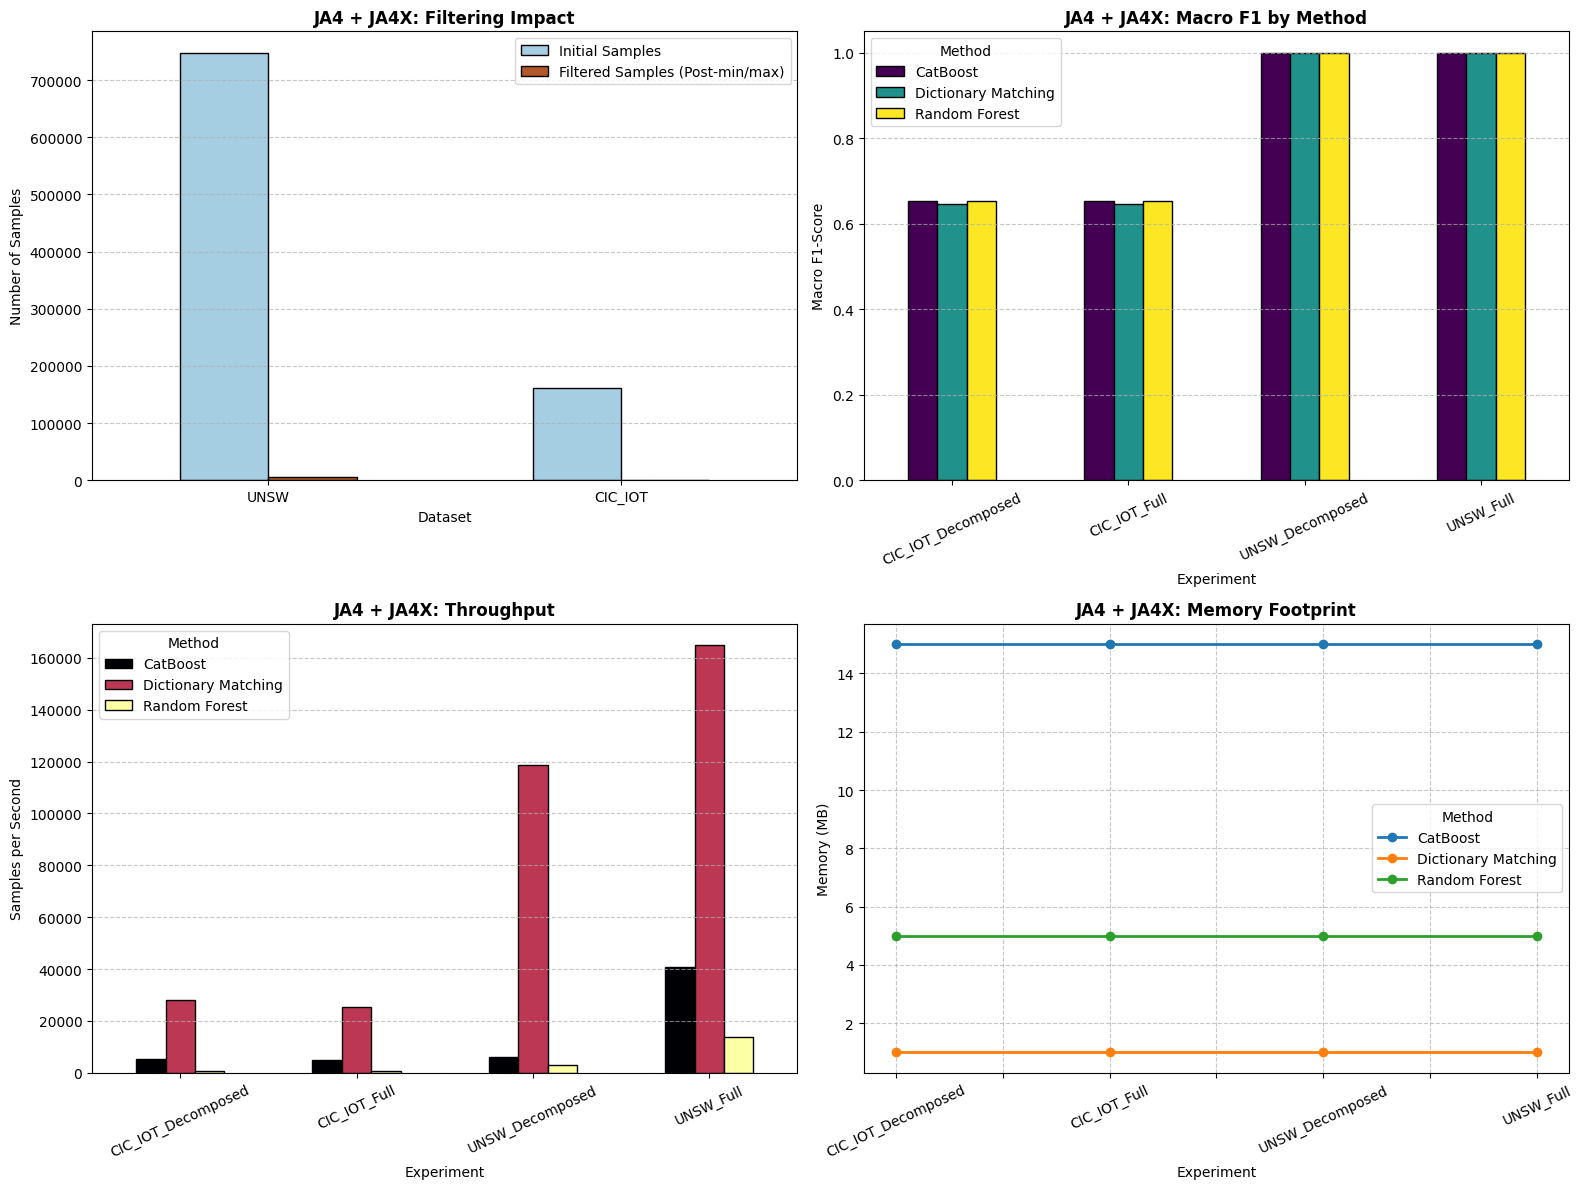

Advanced visualization saved to: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Benchmark_Visualization_JA4X_All_Fingerprints.pdf


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sample_counts = df_audit.set_index("Dataset")[["Initial Samples", "Filtered Samples (Post-min/max)"]]
sample_counts.plot(kind="bar", ax=axes[0, 0], colormap="Paired", edgecolor="black")
axes[0, 0].set_title(f"{COMBINATION_NAME}: Filtering Impact", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Number of Samples", fontsize=10)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 0].tick_params(axis="x", rotation=0)

pivot_f1 = df_summary.pivot(index="Experiment", columns="Method", values="F1-Score (Macro)")
pivot_f1.plot(kind="bar", ax=axes[0, 1], colormap="viridis", edgecolor="black")
axes[0, 1].set_title(f"{COMBINATION_NAME}: Macro F1 by Method", fontsize=12, fontweight="bold")
axes[0, 1].set_ylabel("Macro F1-Score", fontsize=10)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 1].tick_params(axis="x", rotation=25)

pivot_throughput = df_summary.pivot(index="Experiment", columns="Method", values="Throughput (samples/s)")
pivot_throughput.plot(kind="bar", ax=axes[1, 0], colormap="inferno", edgecolor="black")
axes[1, 0].set_title(f"{COMBINATION_NAME}: Throughput", fontsize=12, fontweight="bold")
axes[1, 0].set_ylabel("Samples per Second", fontsize=10)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[1, 0].tick_params(axis="x", rotation=25)

pivot_memory = df_summary.pivot(index="Experiment", columns="Method", values="Memory (MB)")
pivot_memory.plot(kind="line", marker="o", ax=axes[1, 1], linewidth=2)
axes[1, 1].set_title(f"{COMBINATION_NAME}: Memory Footprint", fontsize=12, fontweight="bold")
axes[1, 1].set_ylabel("Memory (MB)", fontsize=10)
axes[1, 1].grid(True, linestyle="--", alpha=0.7)
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
combined_plot_path = os.path.join(OUTPUT_DIR, "Benchmark_Visualization_JA4X_All_Fingerprints.pdf")
plt.savefig(combined_plot_path, format="pdf", bbox_inches="tight")
plt.show()
print(f"Advanced visualization saved to: {combined_plot_path}")

### Individual Timing Figures

The following figures compare each method separately for training time, inference latency and throughput. The experiment labels distinguish datasets and Full versus Decomposed representations.

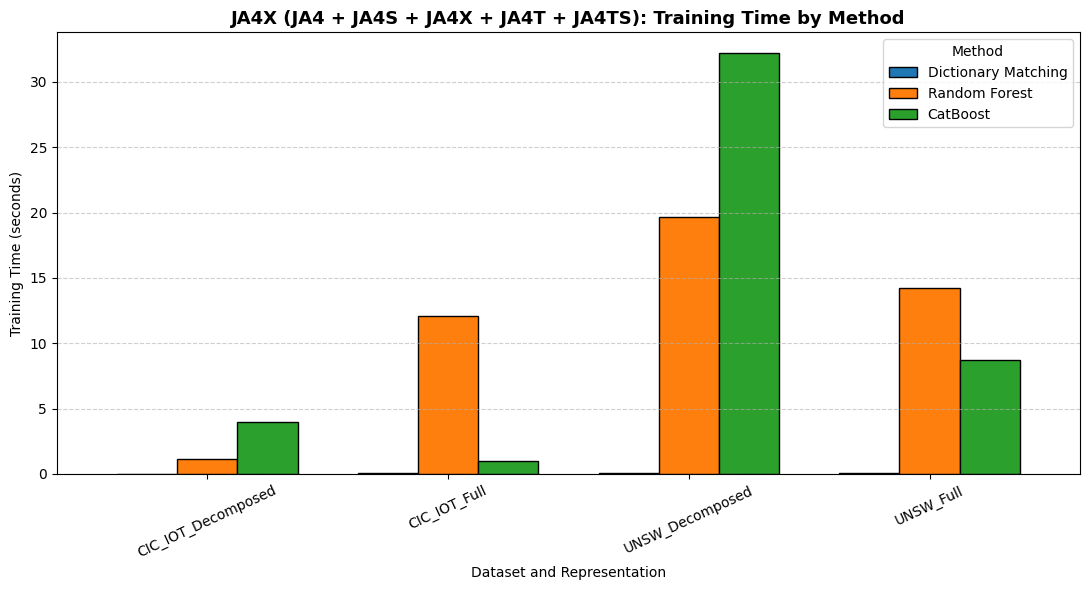

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4X_ALL_FINGERPRINTS_training_time.pdf


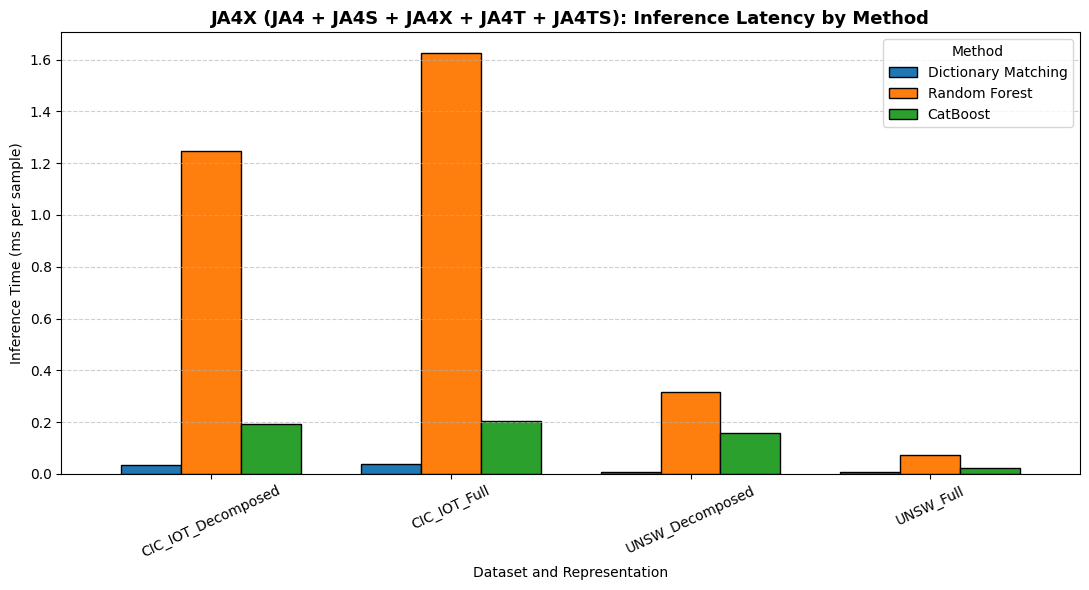

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4X_ALL_FINGERPRINTS_inference_latency.pdf


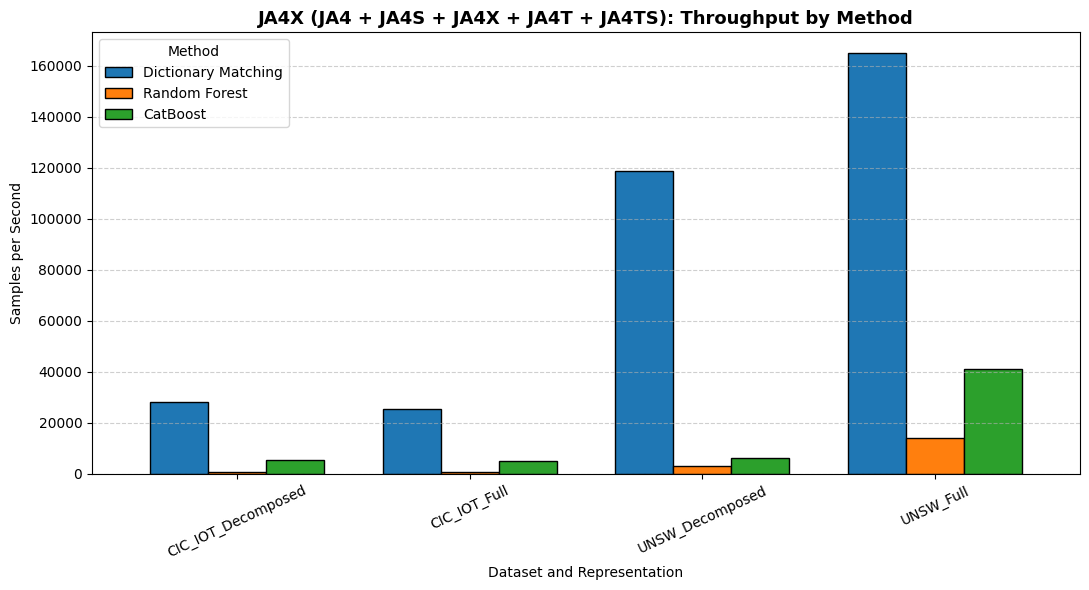

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4X_ALL_FINGERPRINTS_throughput.pdf


In [11]:
import os
import matplotlib.pyplot as plt
import pandas as pd

COMBINATION_LABEL = "JA4X (JA4 + JA4S + JA4X + JA4T + JA4TS)"
OUTPUT_TAG = "JA4X_ALL_FINGERPRINTS"
TIMING_OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(TIMING_OUTPUT_DIR, exist_ok=True)
timing_results = pd.DataFrame(all_global_results)
method_order = ["Dictionary Matching", "Random Forest", "CatBoost"]
timing_metrics = [
    ("Training Time (s)", "Training Time by Method", "Training Time (seconds)", "training_time"),
    ("Inference Time (ms/sample)", "Inference Latency by Method", "Inference Time (ms per sample)", "inference_latency"),
    ("Throughput (samples/s)", "Throughput by Method", "Samples per Second", "throughput")
]


for metric, title, y_label, file_suffix in timing_metrics:
    timing_pivot = timing_results.pivot_table(
        index="Experiment", columns="Method", values=metric, aggfunc="mean"
    )
    timing_pivot = timing_pivot.reindex(columns=[method for method in method_order if method in timing_pivot.columns])
    ax = timing_pivot.plot(kind="bar", figsize=(11, 6), edgecolor="black", width=0.75)
    ax.set_title(f"{COMBINATION_LABEL}: {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Dataset and Representation", fontsize=10)
    ax.set_ylabel(y_label, fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(title="Method")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    figure_path = os.path.join(TIMING_OUTPUT_DIR, f"{OUTPUT_TAG}_{file_suffix}.pdf")
    ax.figure.savefig(figure_path, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)
    print(f"Saved: {figure_path}")

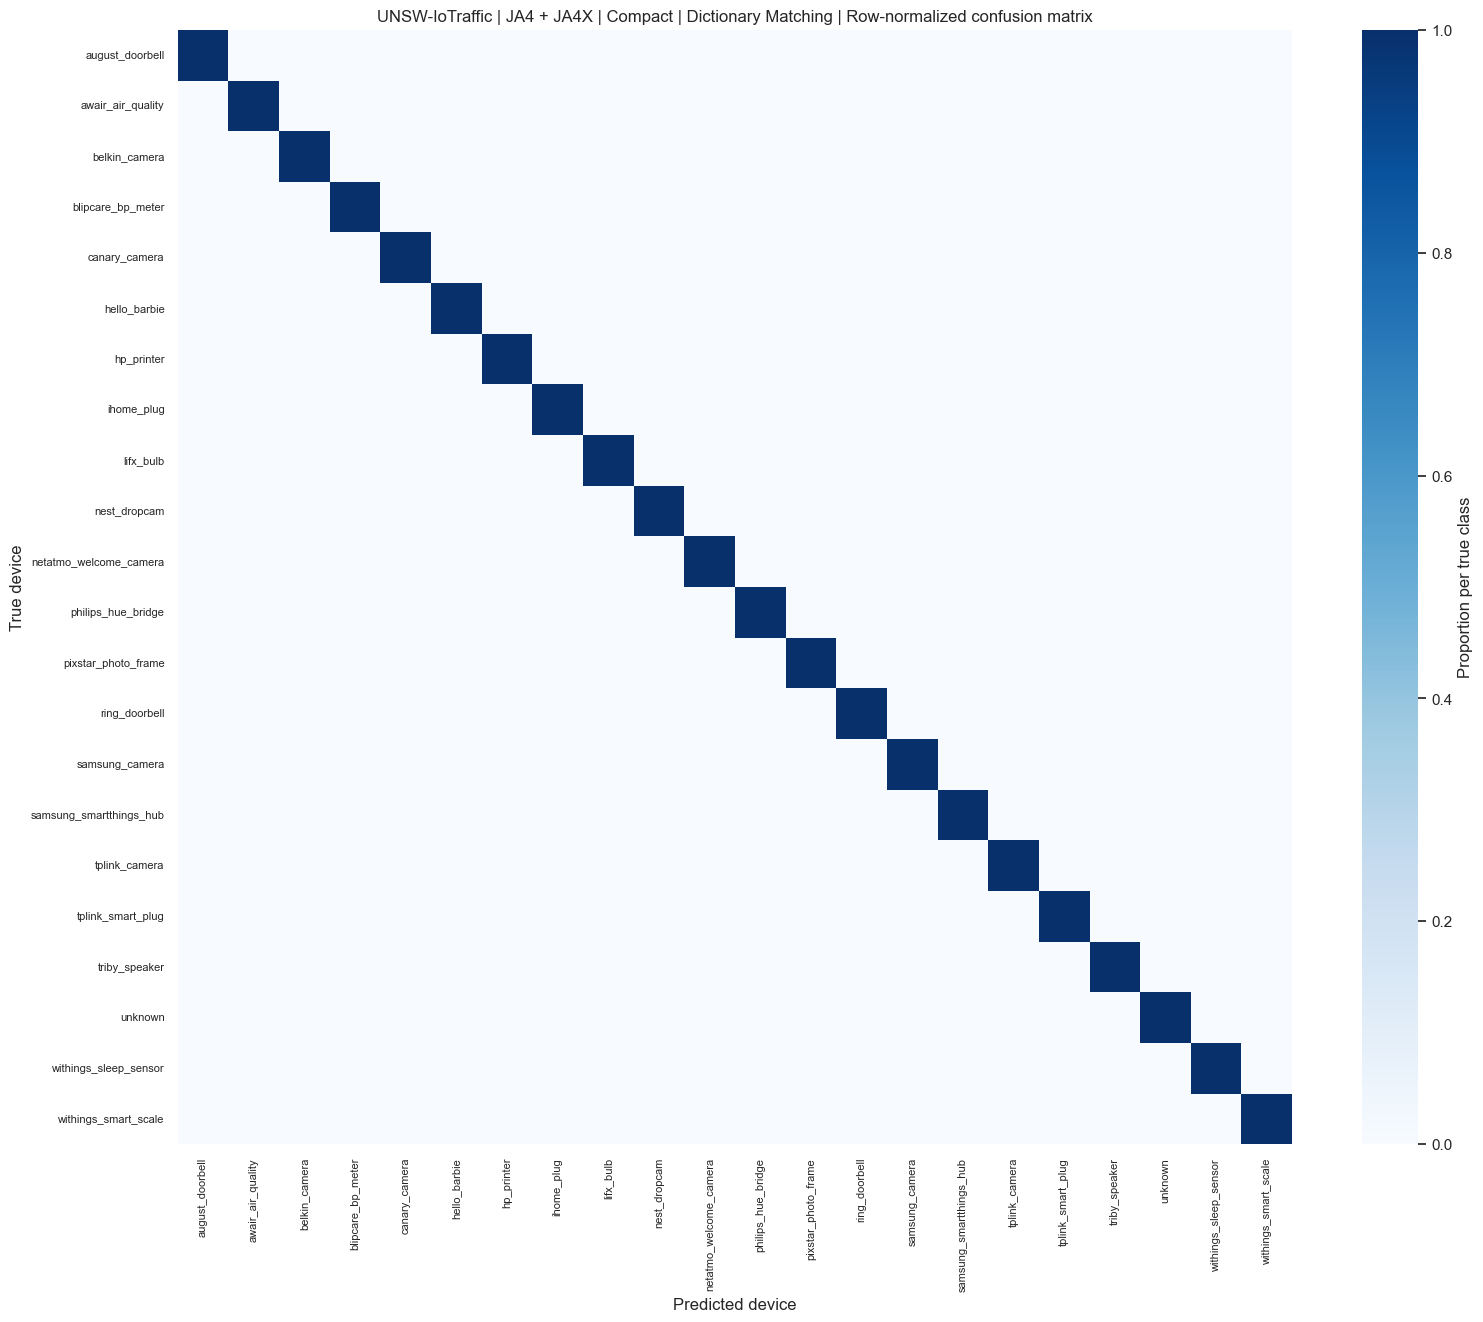

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Compact_Dictionary_Matching_confusion_matrix.pdf


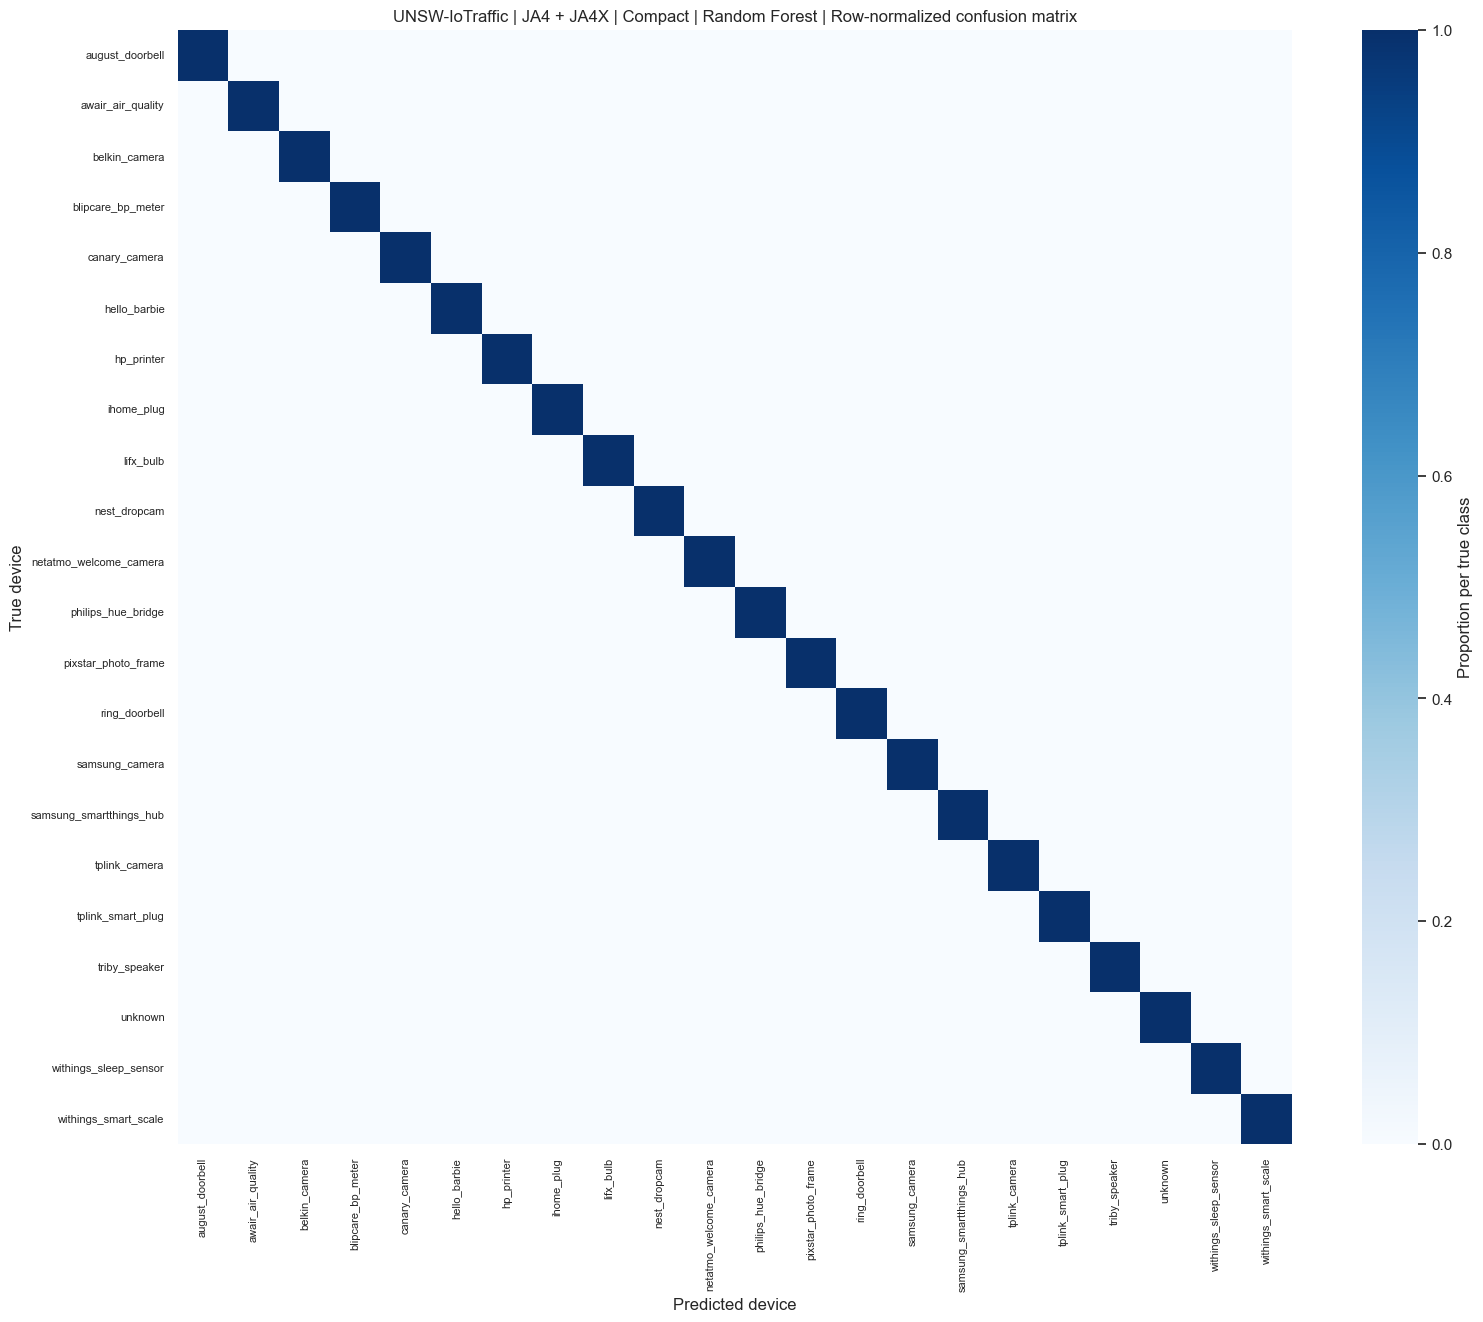

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Compact_Random_Forest_confusion_matrix.pdf


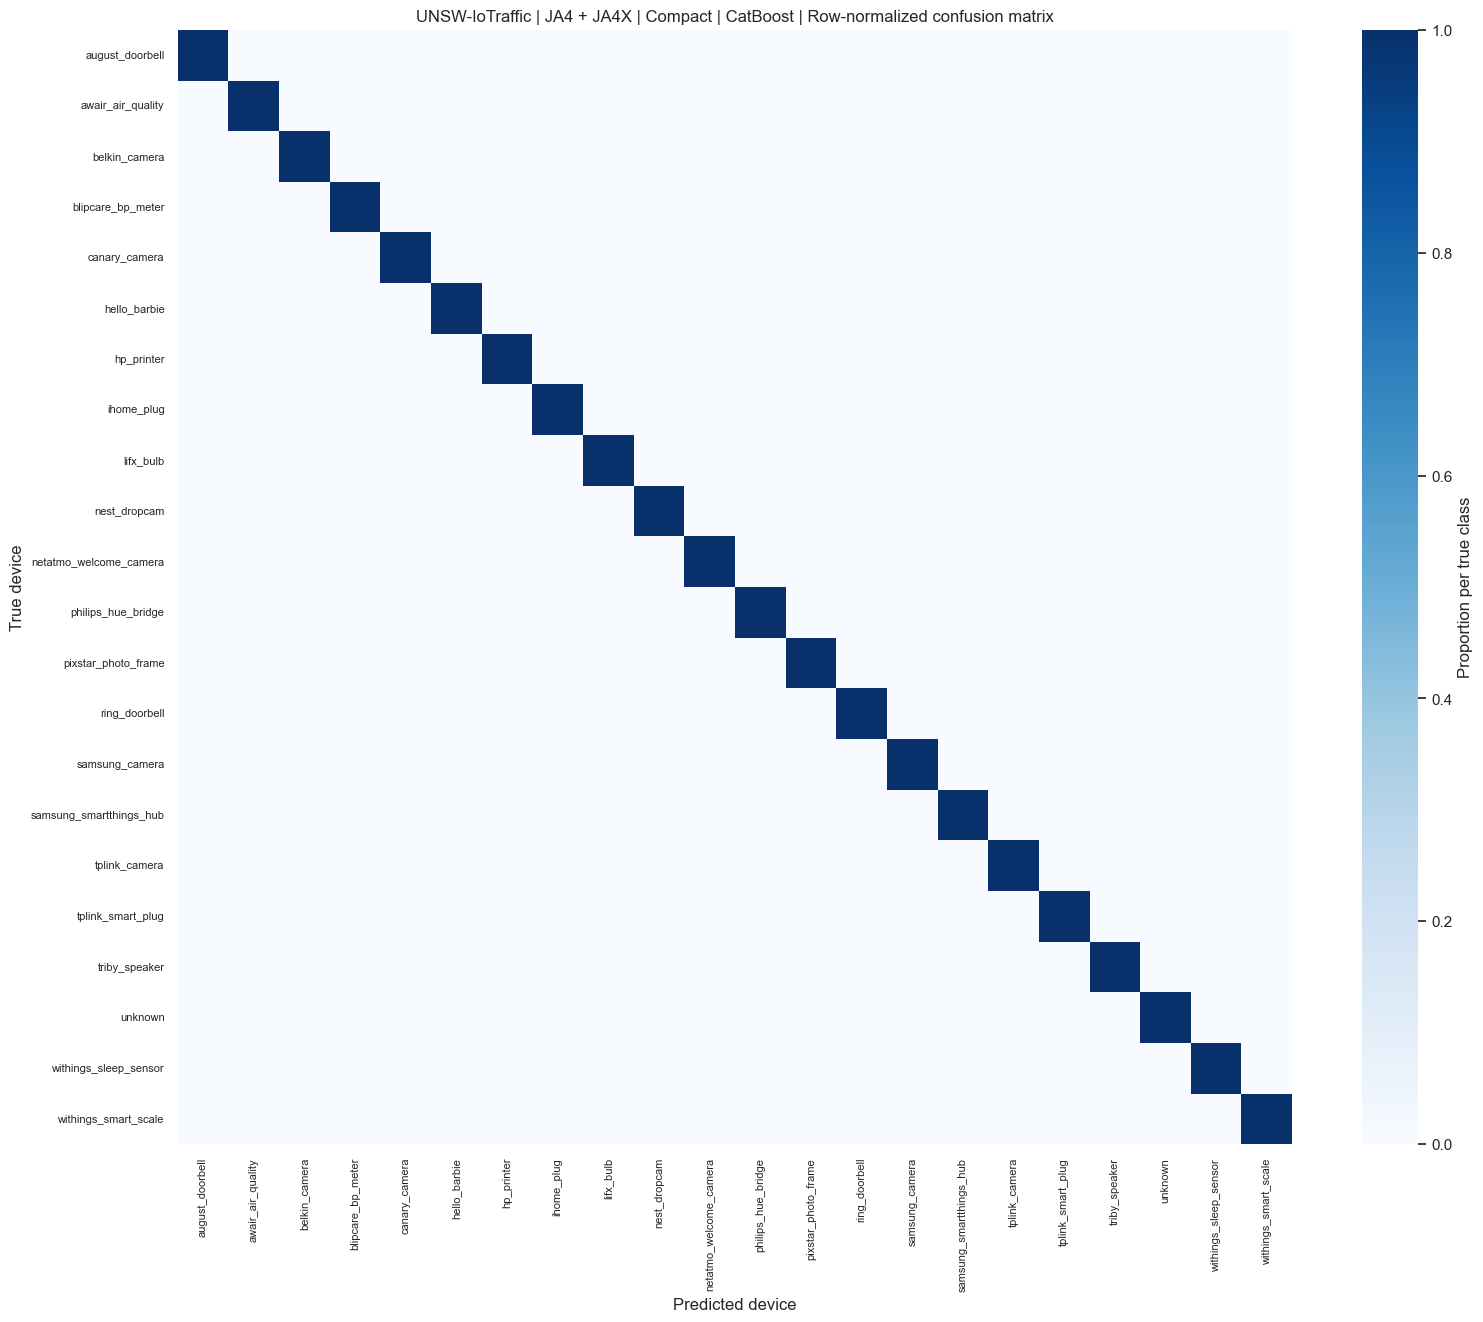

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Compact_CatBoost_confusion_matrix.pdf


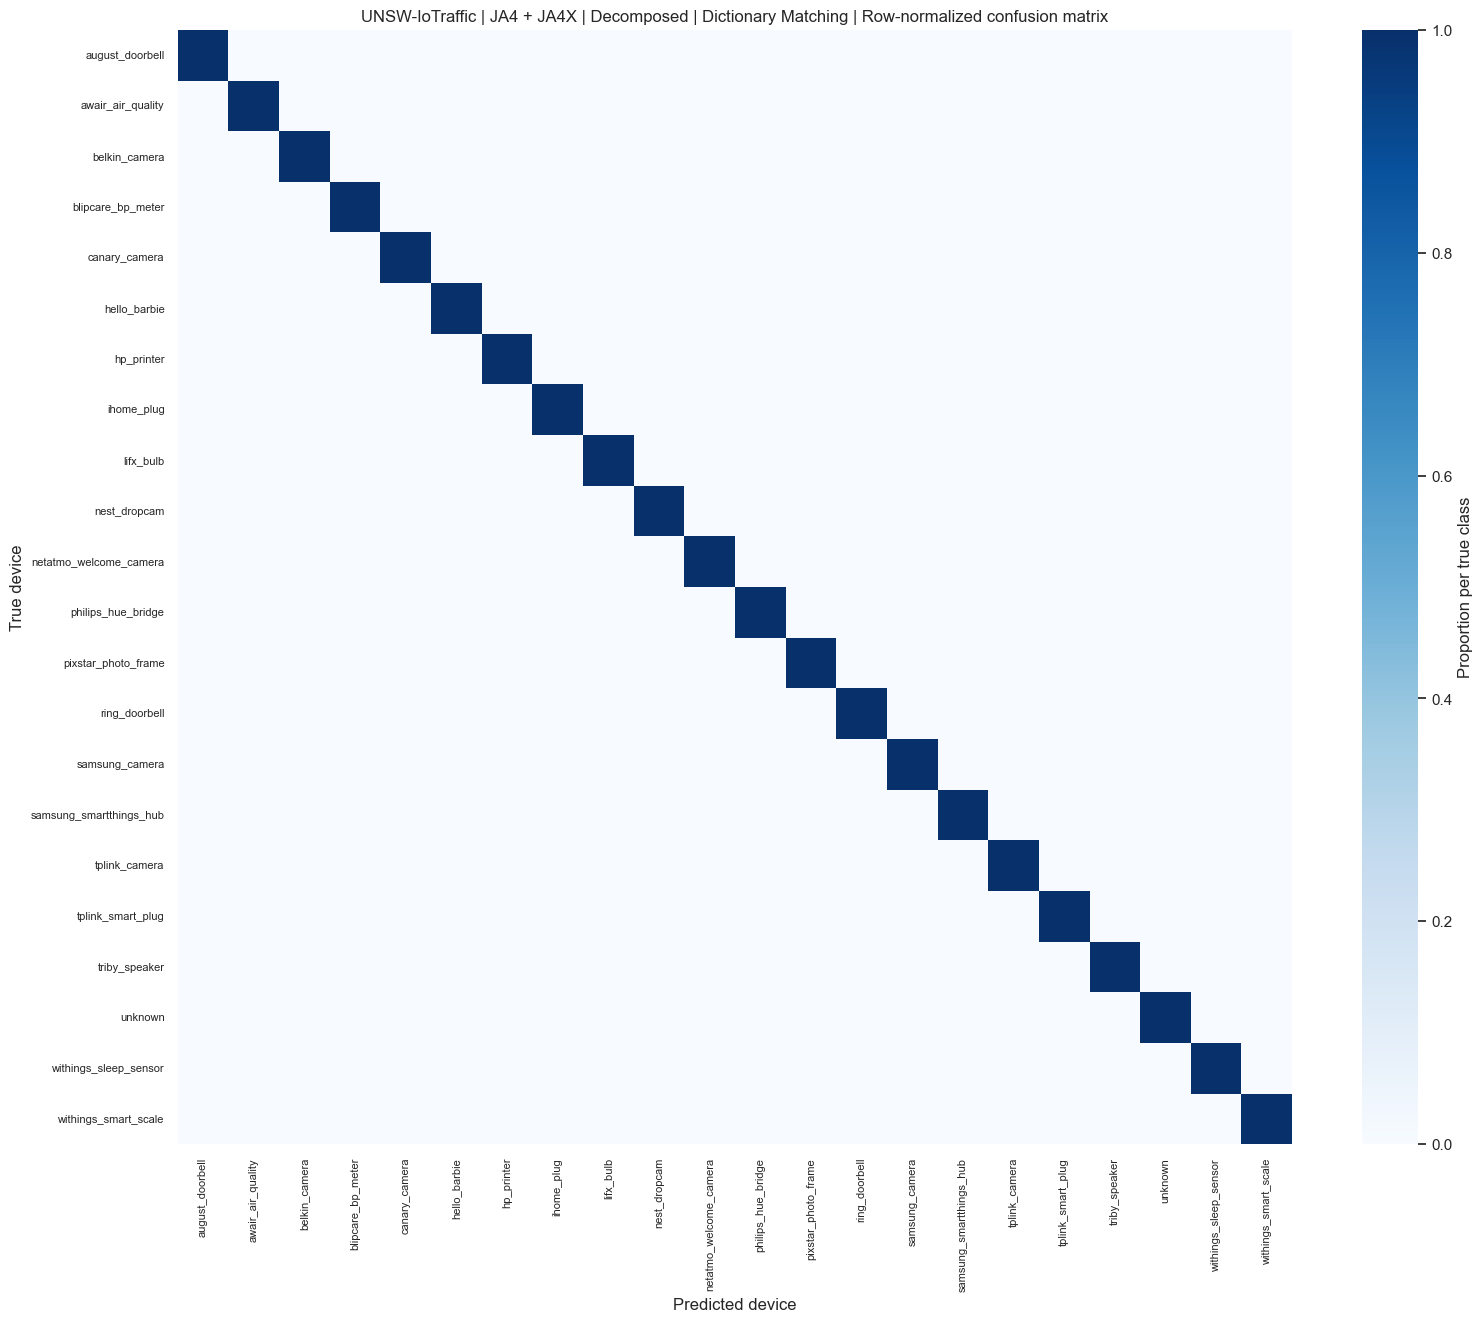

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Decomposed_Dictionary_Matching_confusion_matrix.pdf


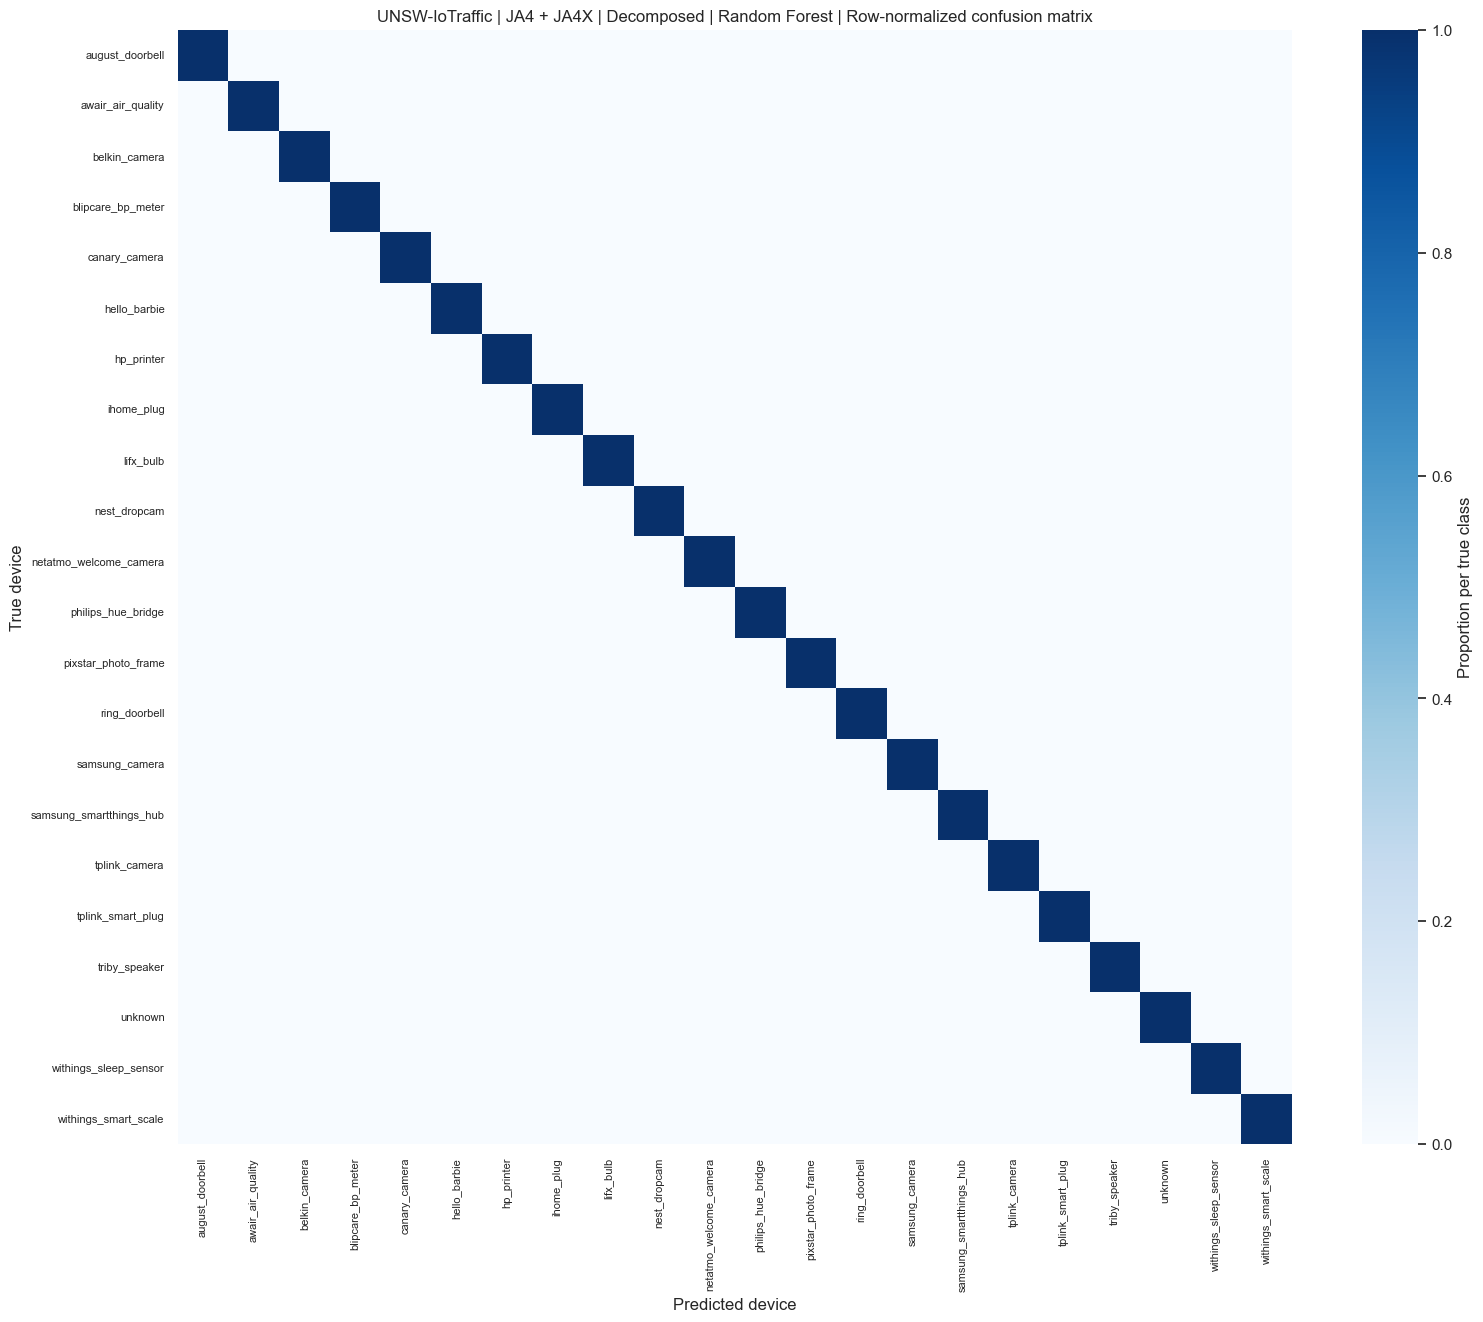

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Decomposed_Random_Forest_confusion_matrix.pdf


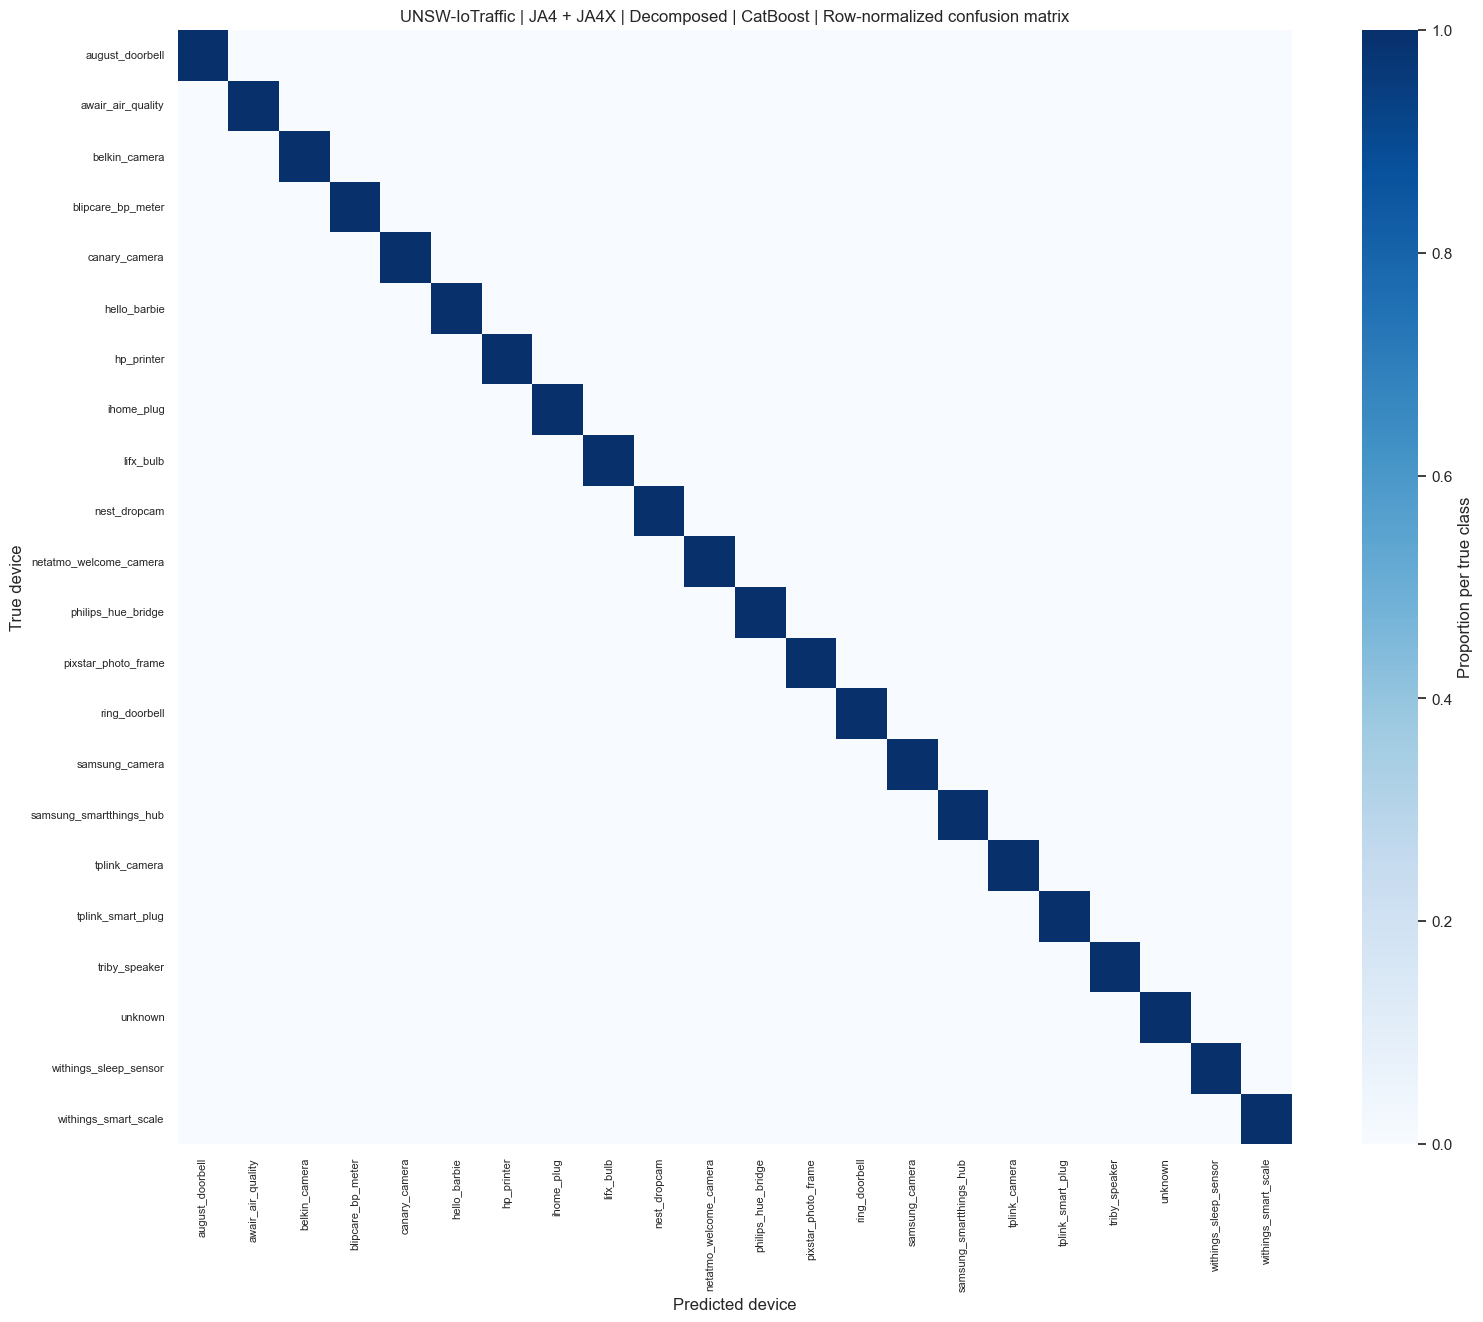

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Decomposed_CatBoost_confusion_matrix.pdf


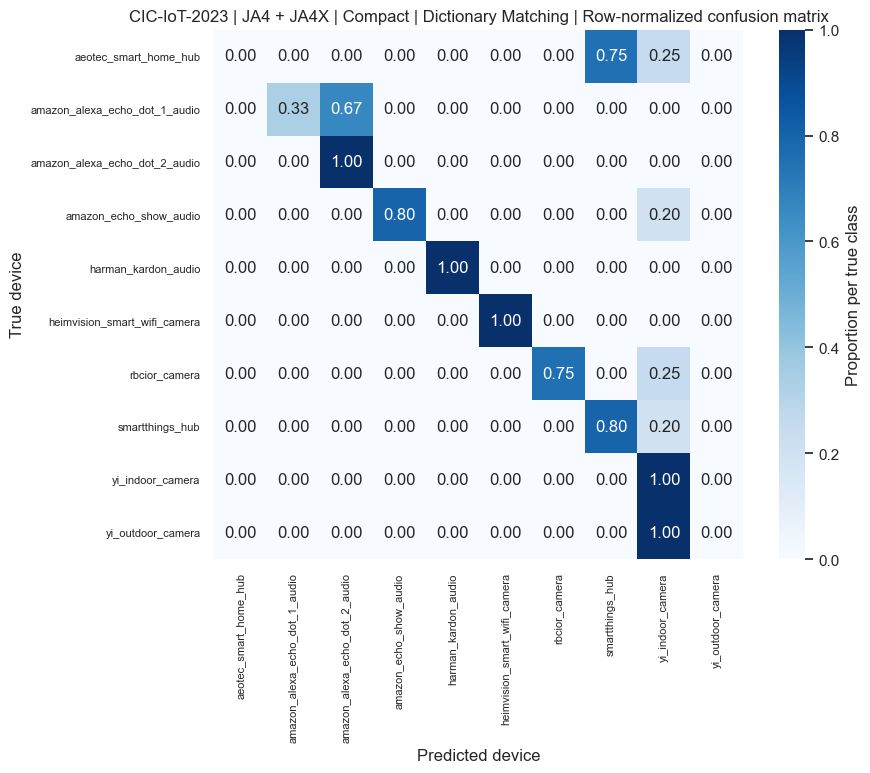

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Compact_Dictionary_Matching_confusion_matrix.pdf


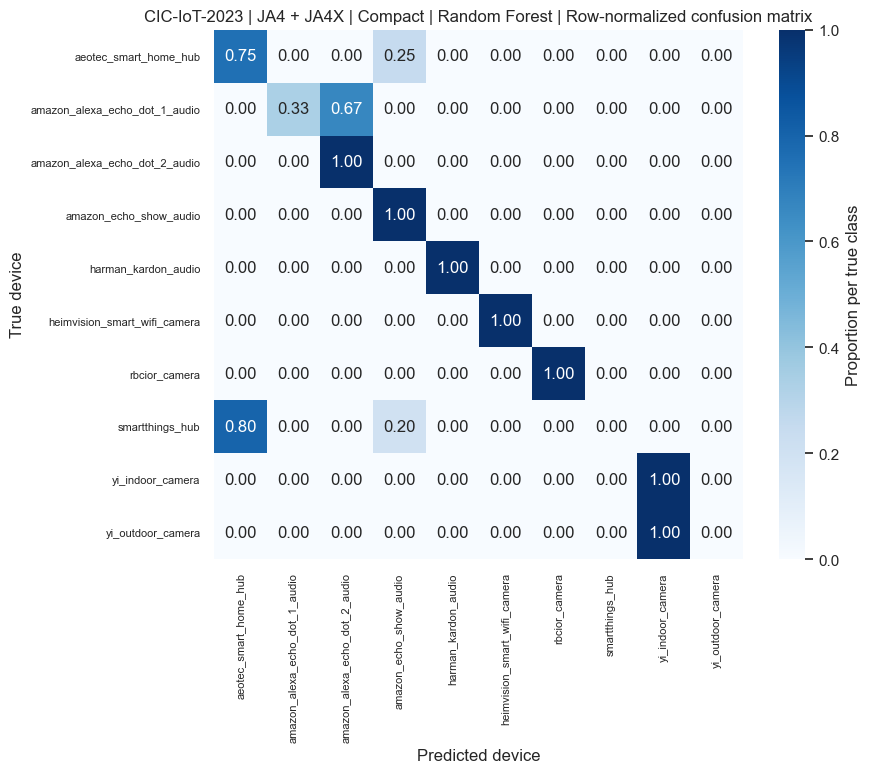

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Compact_Random_Forest_confusion_matrix.pdf


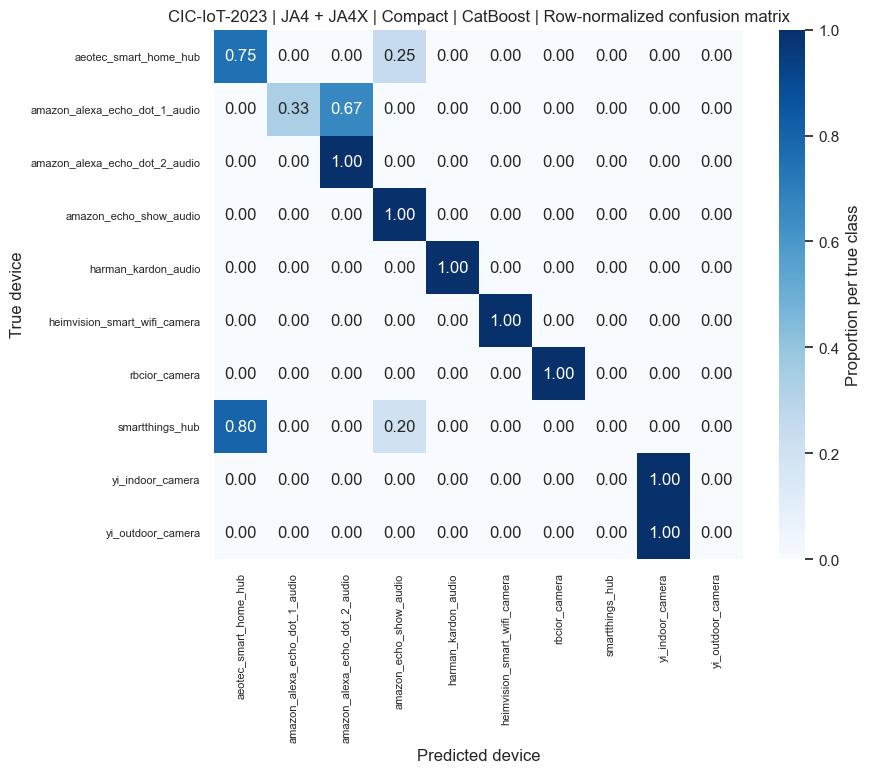

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Compact_CatBoost_confusion_matrix.pdf


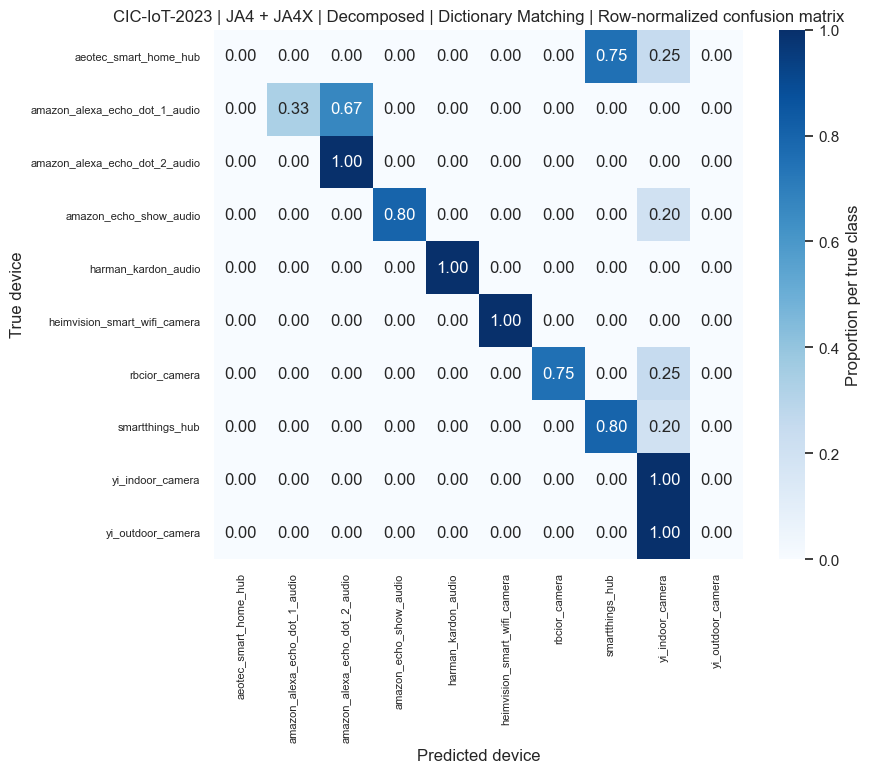

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Decomposed_Dictionary_Matching_confusion_matrix.pdf


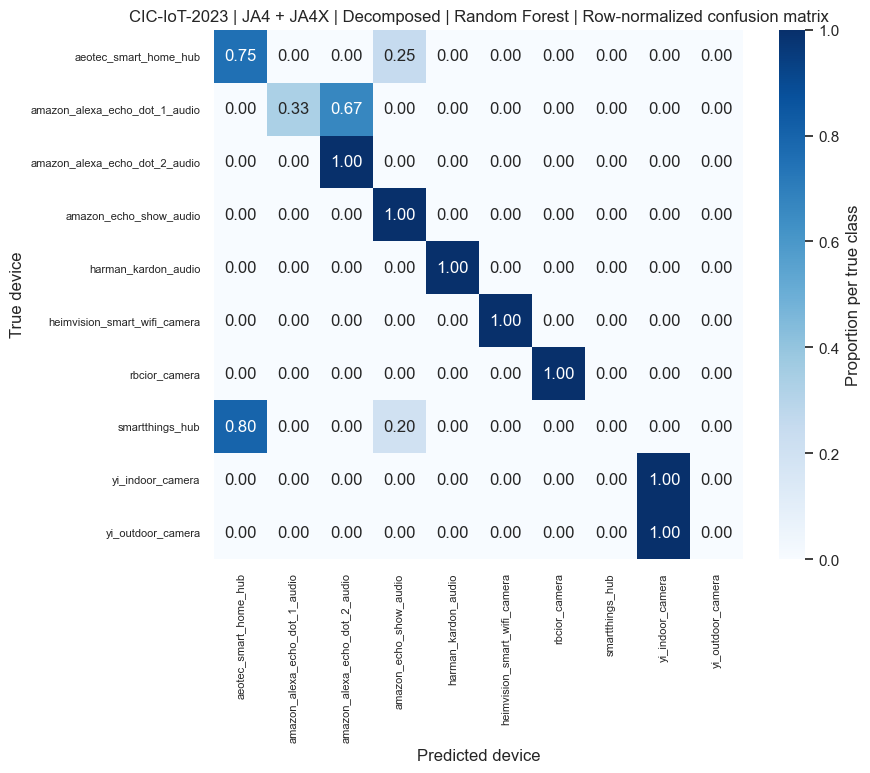

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Decomposed_Random_Forest_confusion_matrix.pdf


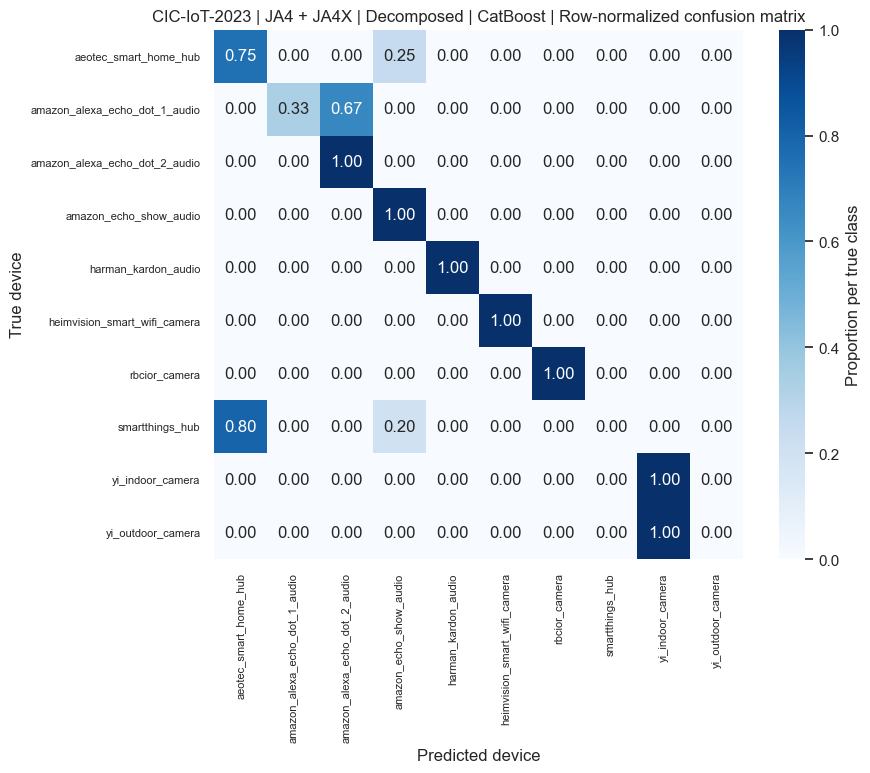

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Decomposed_CatBoost_confusion_matrix.pdf
EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4 + JA4X | UNSW
[Fingerprint Stats] Total valid samples: 746433
[Fingerprint Stats] Unique JA4 + JA4X bundles: 68 (0.01%)
[Fingerprint Stats] Repeated JA4 + JA4X bundles: 746365 (99.99%)


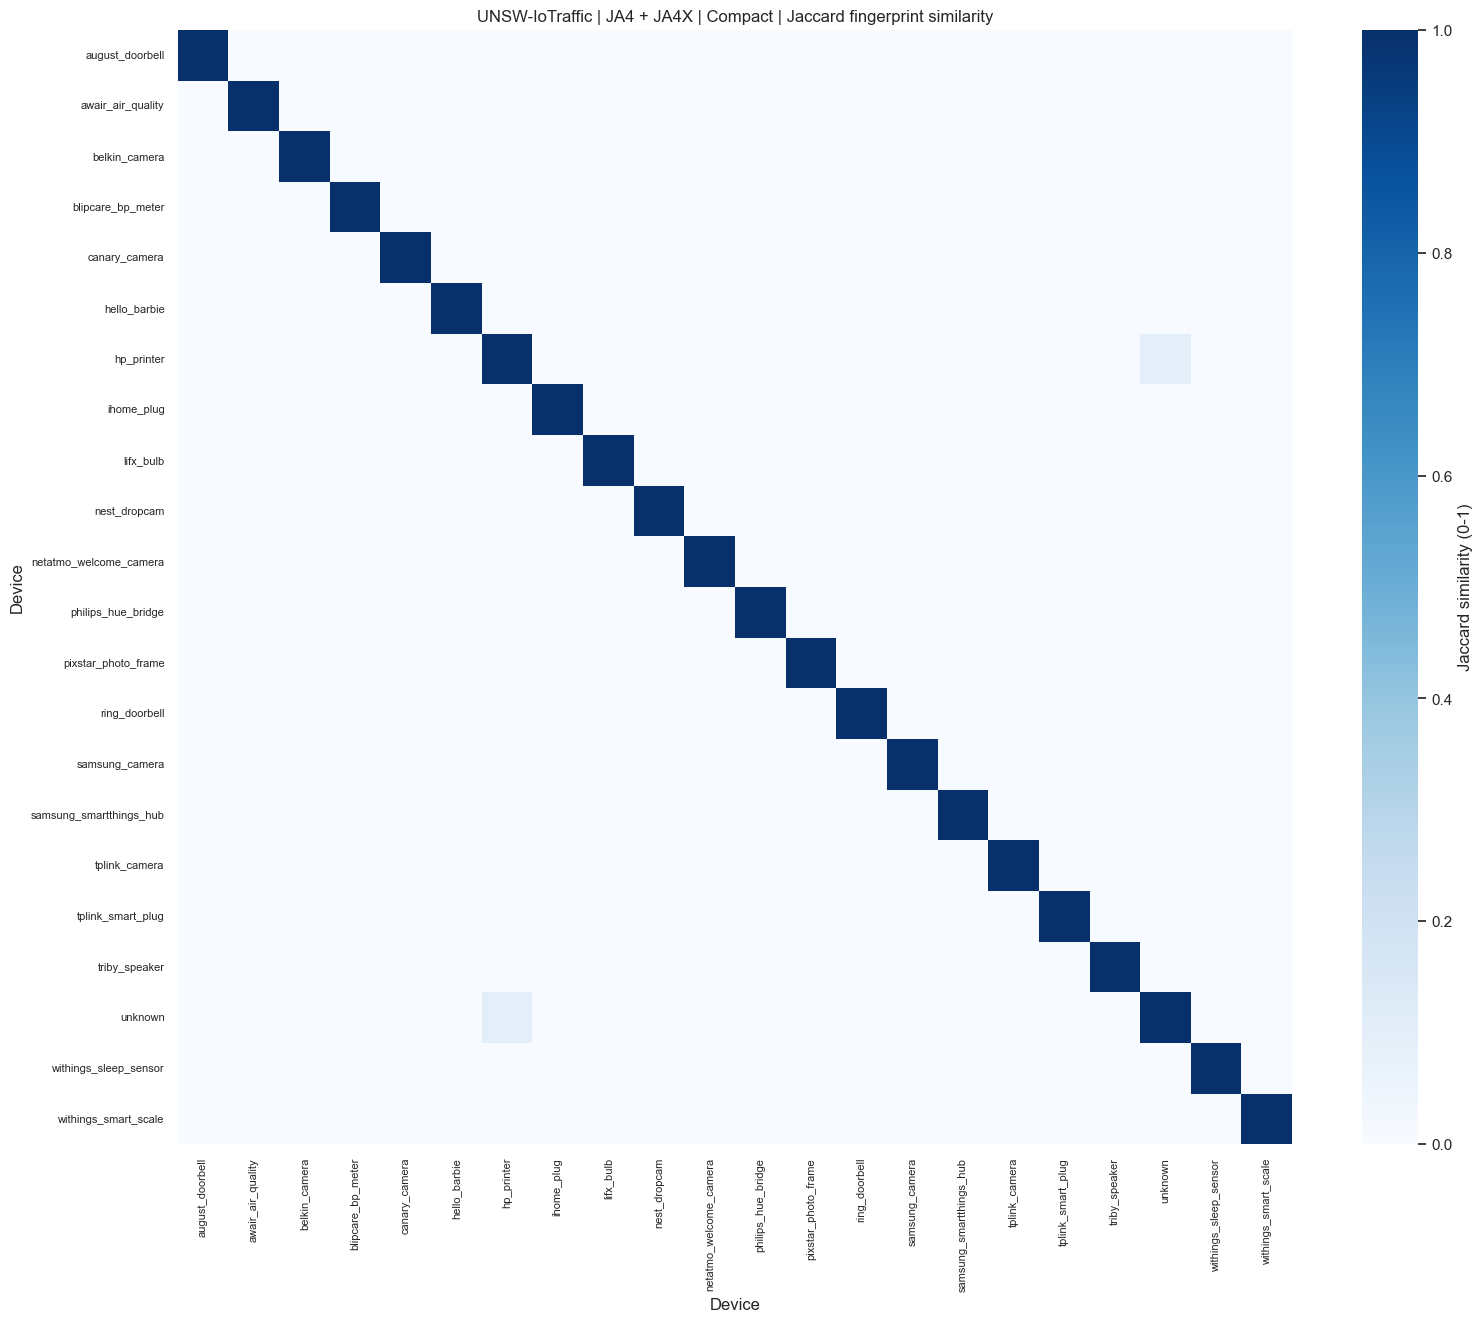

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Compact_jaccard_similarity.pdf


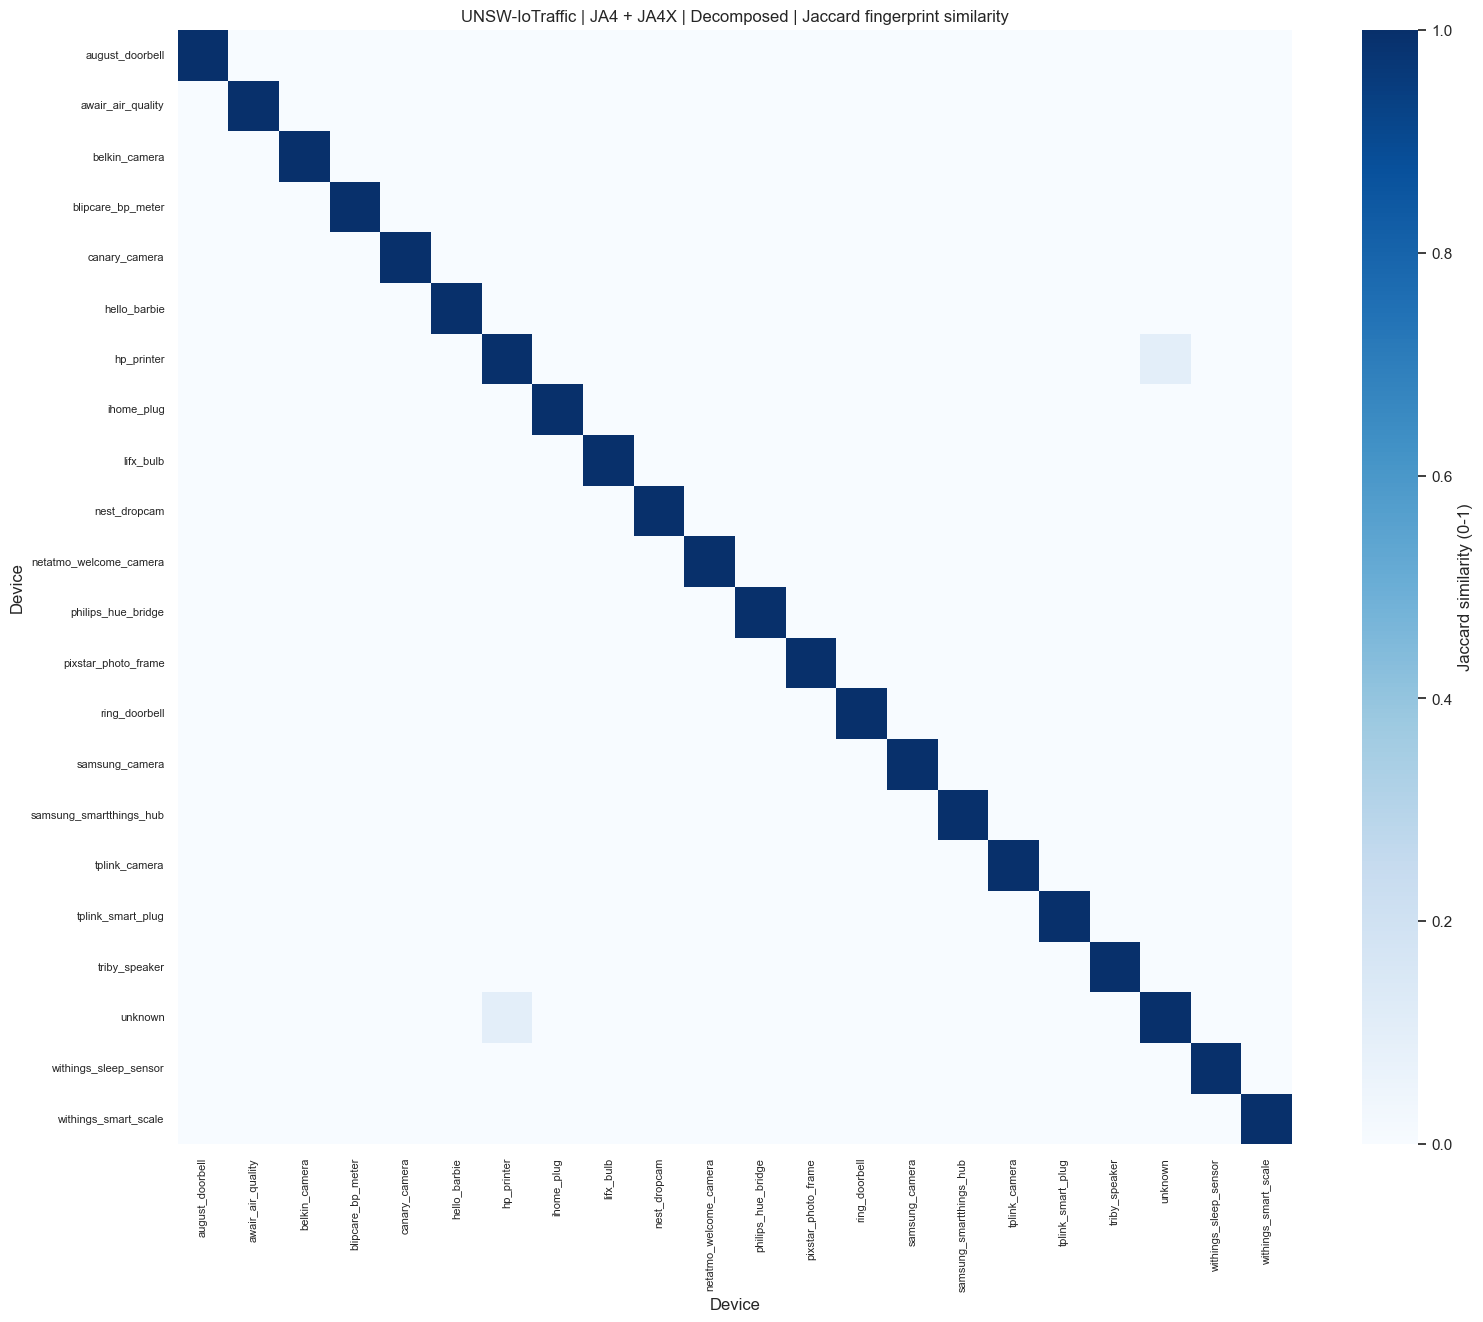

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4X_Decomposed_jaccard_similarity.pdf
EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4 + JA4X | CIC_IOT
[Fingerprint Stats] Total valid samples: 323
[Fingerprint Stats] Unique JA4 + JA4X bundles: 21 (6.50%)
[Fingerprint Stats] Repeated JA4 + JA4X bundles: 302 (93.50%)


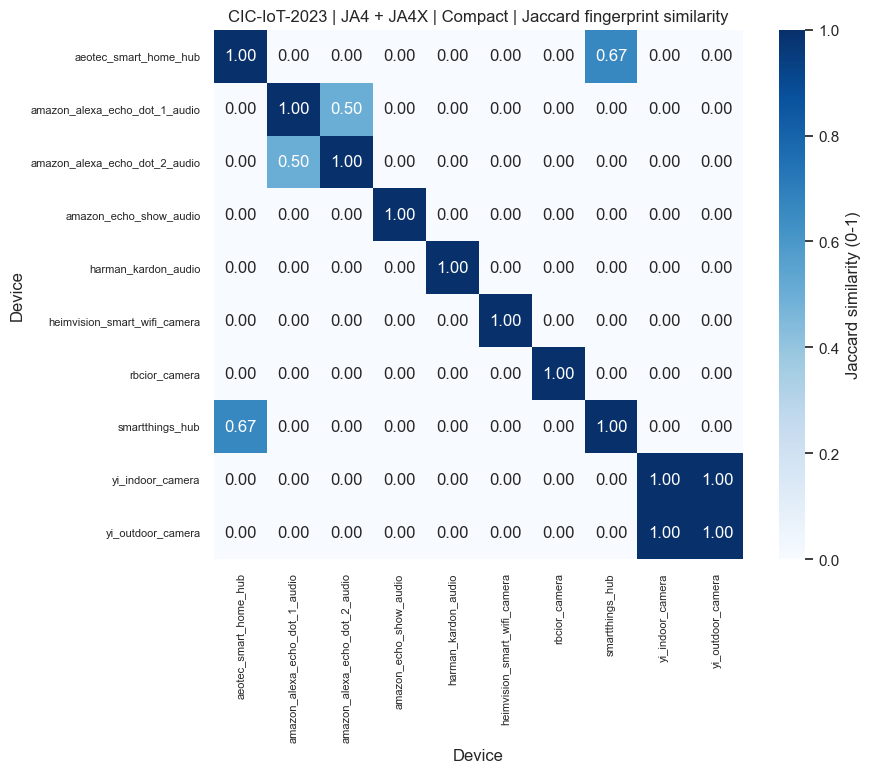

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Compact_jaccard_similarity.pdf


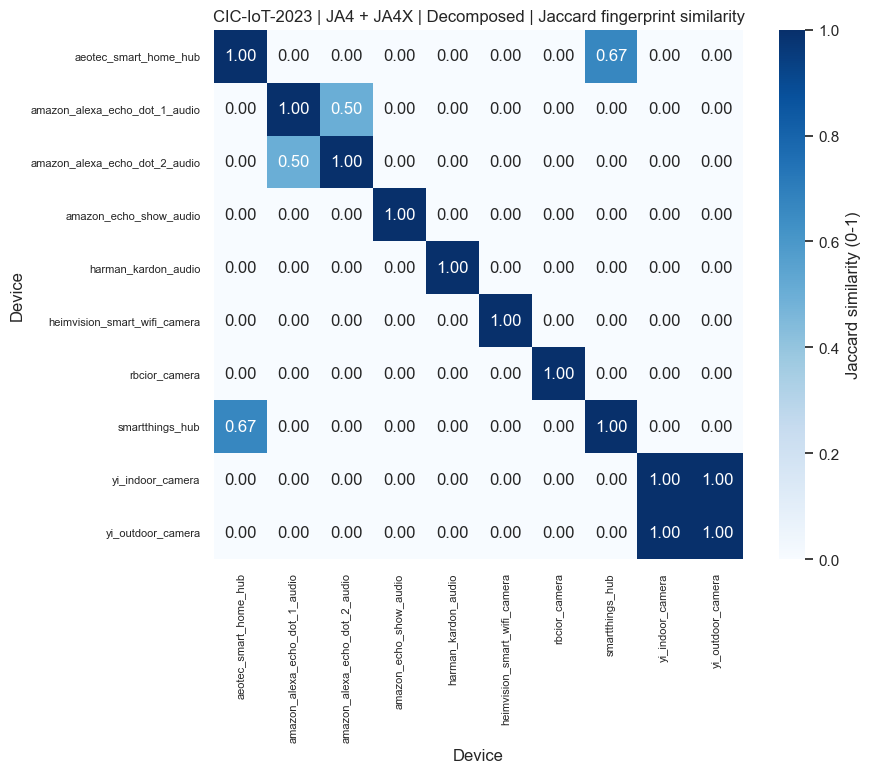

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4X_Decomposed_jaccard_similarity.pdf
Generated 12 normalized confusion matrices and 4 Jaccard similarity matrices as individual PDFs.


In [12]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

if "benchmark_prediction_records" not in globals() or not benchmark_prediction_records:
    raise RuntimeError("Run the dataset benchmark cell before generating matrices.")

matrix_output_dir = os.path.join(OUTPUT_DIR, "similarity_and_confusion_matrices")
os.makedirs(matrix_output_dir, exist_ok=True)
latest_records = {record["Experiment"]: record for record in benchmark_prediction_records}
fingerprint_label = " + ".join(feature.upper() for feature in FULL_FEATURES)

def make_file_stem(value):
    return str(value).replace("+", "plus").replace(" ", "_").replace("/", "_").replace(":", "").replace("(", "").replace(")", "")

sns.set_theme(style="white")
confusion_matrix_count = 0
for record in latest_records.values():
    class_names = np.asarray(record["class_names"])
    class_labels = np.arange(len(class_names))
    true_labels = np.asarray(record["y_true"])
    experiment_name = record["Experiment"]
    dataset_name = "CIC-IoT-2023" if experiment_name.startswith("CIC_IOT") else "UNSW-IoTraffic"
    representation_name = "Decomposed" if experiment_name.endswith("_Decomposed") else "Compact"
    for algorithm_name, predicted_labels in record["predictions"].items():
        raw_matrix = confusion_matrix(true_labels, np.asarray(predicted_labels), labels=class_labels)
        row_totals = raw_matrix.sum(axis=1, keepdims=True)
        normalized_matrix = np.divide(raw_matrix, row_totals, out=np.zeros(raw_matrix.shape, dtype=float), where=row_totals != 0)
        side_length = max(9, min(20, 4 + 0.55 * len(class_names)))
        figure, axis = plt.subplots(figsize=(side_length, side_length * 0.82))
        sns.heatmap(normalized_matrix, ax=axis, cmap="Blues", vmin=0, vmax=1, square=True,
                    annot=len(class_names) <= 12, fmt=".2f", xticklabels=class_names, yticklabels=class_names,
                    cbar_kws={"label": "Proportion per true class"})
        axis.set_title(f"{dataset_name} | {fingerprint_label} | {representation_name} | {algorithm_name} | Row-normalized confusion matrix")
        axis.set_xlabel("Predicted device")
        axis.set_ylabel("True device")
        axis.tick_params(axis="x", labelrotation=90, labelsize=8)
        axis.tick_params(axis="y", labelrotation=0, labelsize=8)
        figure.tight_layout()
        file_stem = make_file_stem(f"{dataset_name}_{fingerprint_label}_{representation_name}_{algorithm_name}_confusion_matrix")
        figure_path = os.path.join(matrix_output_dir, f"{file_stem}.pdf")
        figure.savefig(figure_path, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        confusion_matrix_count += 1
        print(f"Saved confusion matrix: {figure_path}")

similarity_matrix_count = 0
for dataset_key, dataset_config in DATASETS_CONFIG.items():
    cleaned_dataset, _ = analyze_and_clean_dataset(dataset_config["path"], dataset_config["min_samples"], dataset_config["max_samples"], dataset_name=dataset_key)
    dataset_name = "CIC-IoT-2023" if dataset_key == "CIC_IOT" else "UNSW-IoTraffic"
    class_names = sorted(cleaned_dataset[TARGET_COL].unique())
    for representation_name, feature_columns in [("Compact", FULL_FEATURES), ("Decomposed", DECOMPOSED_FEATURES)]:
        fingerprints_by_class = {}
        for class_name in class_names:
            class_rows = cleaned_dataset.loc[cleaned_dataset[TARGET_COL] == class_name, feature_columns]
            fingerprints_by_class[class_name] = set(map(tuple, class_rows.fillna("unknown").astype(str).to_numpy()))
        similarity_matrix = np.eye(len(class_names), dtype=float)
        for row_index, first_class in enumerate(class_names):
            for column_index in range(row_index + 1, len(class_names)):
                second_class = class_names[column_index]
                first_fingerprints = fingerprints_by_class[first_class]
                second_fingerprints = fingerprints_by_class[second_class]
                union_size = len(first_fingerprints | second_fingerprints)
                similarity = len(first_fingerprints & second_fingerprints) / union_size if union_size else 0.0
                similarity_matrix[row_index, column_index] = similarity
                similarity_matrix[column_index, row_index] = similarity
        side_length = max(9, min(20, 4 + 0.55 * len(class_names)))
        figure, axis = plt.subplots(figsize=(side_length, side_length * 0.82))
        sns.heatmap(similarity_matrix, ax=axis, cmap="Blues", vmin=0, vmax=1, square=True,
                    annot=len(class_names) <= 12, fmt=".2f", xticklabels=class_names, yticklabels=class_names,
                    cbar_kws={"label": "Jaccard similarity (0-1)"})
        axis.set_title(f"{dataset_name} | {fingerprint_label} | {representation_name} | Jaccard fingerprint similarity")
        axis.set_xlabel("Device")
        axis.set_ylabel("Device")
        axis.tick_params(axis="x", labelrotation=90, labelsize=8)
        axis.tick_params(axis="y", labelrotation=0, labelsize=8)
        figure.tight_layout()
        file_stem = make_file_stem(f"{dataset_name}_{fingerprint_label}_{representation_name}_jaccard_similarity")
        figure_path = os.path.join(matrix_output_dir, f"{file_stem}.pdf")
        figure.savefig(figure_path, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        similarity_matrix_count += 1
        print(f"Saved similarity matrix: {figure_path}")

print(f"Generated {confusion_matrix_count} normalized confusion matrices and {similarity_matrix_count} Jaccard similarity matrices as individual PDFs.")